In [1]:
import os, re, sys, importlib, glob
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from geopy.distance import geodesic, great_circle
from scipy.stats import ttest_ind
import baltic as bt
from scipy.special import binom
from collections import defaultdict, Counter
import arviz as az

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html


In [2]:
# Goal: this script allows me to plot data from the MCC continuous phylogeography tree

In [3]:
def get_season(y):

    y_r = round(y, 5)
    
    if y_r <= 2021.96986: # late autumn 2021
        return "autumn_2021"
    elif 2021.96986 < y_r <= 2022.21096: # winter 2021-22
        return "winter_2021/22"
    elif 2022.21096 < y_r <= 2022.46575: # spring 2022
        return "spring_2022"
    elif 2022.46575 < y_r <= 2022.72055: # summer 2022
        return "summer_2022"
    elif 2022.72055 < y_r <= 2022.96712: # autumn 2022
        return "autumn_2022"
    elif 2022.96712 < y_r <= 2023.21096: # winter 2022-23
        return "winter_2022/23"
    elif 2023.21096 < y_r <= 2023.46575: # spring 2023
        return "spring_2023"
    elif 2023.46575 < y_r <= 2023.72329: # summer 2023
        return "summer_2023"
    elif 2023.72329 < y_r <= 2023.96712: # autumn 2023
        return "autumn_2023"
    elif 2023.96712 < y_r <= 2024.21038: # winter 2023-24
        return "winter_2023/24"
    elif 2024.21038 < y_r <= 2024.46448: # spring 2024
        return "spring_2024"
    elif 2024.46448 < y_r <= 2024.72131: # summer 2024
        return "summer_2024"
    elif 2024.72131 < y_r <= 2024.96721: # autumn 2024
        return "autumn_2024"
    elif y_r > 2024.96721: # winter 2024
        return "winter_2024"
    else:
        return "unknown"

In [4]:
def get_month(y):

    y_r = round(y, 5)
    
    if 2021.665753 <= y_r < 2021.747945: 
        return "september"
    elif 2021.747945 <= y_r < 2021.832877: 
        return "october"
    elif 2021.832877 <= y_r < 2021.915068: 
        return "november"
    elif 2021.915068 <= y_r < 2022.000000: 
        return "december"
    elif 2022.000000 <= y_r < 2022.084932: 
        return "january"
    elif 2022.084932 <= y_r < 2022.161644:
        return "february"
    elif 2022.161644 <= y_r < 2022.246575:
        return "march"
    elif 2022.246575 <= y_r < 2022.328767:
        return "april"
    elif 2022.328767 <= y_r < 2022.413699:
        return "may"
    elif 2022.413699 <= y_r < 2022.495890:
        return "june"
    elif 2022.495890 <= y_r < 2022.580822:
        return "july"
    elif 2022.580822 <= y_r < 2022.665753:
        return "august"
    elif 2022.665753 <= y_r < 2022.747945:
        return "september"
    elif 2022.747945 <= y_r < 2022.832877: 
        return "october"
    elif 2022.832877 <= y_r < 2022.915068:
        return "november"
    elif 2022.915068 <= y_r < 2023.000000:
        return "december"
    elif 2023.000000 <= y_r < 2023.084932:
        return "january"
    elif 2023.084932 <= y_r < 2023.161644:
        return "february"
    elif 2023.161644 <= y_r < 2023.246575:
        return "march"
    elif 2023.246575 <= y_r < 2023.328767:
        return "april"
    elif 2023.328767 <= y_r < 2023.413699:
        return "may"
    elif 2023.413699 <= y_r < 2023.495890:
        return "june"
    elif 2023.495890 <= y_r < 2023.580822:
        return "july"
    elif 2023.580822 <= y_r < 2023.665753:
        return "august"
    elif 2023.665753 <= y_r < 2023.747945:
        return "september"
    elif 2023.747945 <= y_r < 2023.832877:
        return "october"
    elif 2023.832877 <= y_r < 2023.915068:
        return "november"
    elif 2023.915068 <= y_r < 2024.000000:
        return "december"
    elif 2024.000000 <= y_r < 2024.084699:
        return "january"
    elif 2024.084699 <= y_r < 2024.163934:
        return "february"
    elif 2024.163934 <= y_r < 2024.248634:
        return "march"
    elif 2024.248634 <= y_r < 2024.330601:
        return "april"
    elif 2024.330601 <= y_r < 2024.415301:
        return "may"
    elif 2024.415301 <= y_r < 2024.497268:
        return "june"
    elif 2024.497268 <= y_r < 2024.581967:
        return "july"
    elif 2024.581967 <= y_r < 2024.666667:
        return "august"
    elif 2024.666667 <= y_r < 2024.748634:
        return "september"
    elif 2024.748634 <= y_r < 2024.833333:
        return "october"
    elif 2024.833333 <= y_r < 2024.915301:
        return "november"
    elif y_r >= 2024.915301:
        return "december"
    else:
        return "unknown"

In [5]:
# Add any required columns

def adding_columns(df):

    df_new = df.copy()

    # Change in latitude and longitude to plot on a scatter plot
    df_new["changeLat"] = df_new["endLat"] - df_new["startLat"]
    df_new["changeLon"] = df_new["endLon"] - df_new["startLon"]

    # Season and year
    df_new["startYear_whole"] = df_new["startYear"].astype(str).str.split(".", expand=True)[0]
    df_new["endYear_whole"] = df_new["endYear"].astype(str).str.split(".", expand=True)[0]
    df_new["seasonYear"] = df_new["startYear"].apply(get_season)
    df_new["season"] = df_new["seasonYear"].str.split("_", expand = True)[0]
    df_new["month"] = df_new["startYear"].apply(get_month)
    df_new["monthYear"] = df_new["startYear_whole"].astype(str) + "_" + df_new["month"].astype(str)
    
    # Trait transitions (these are not Markov jumps but they'll serve that purpose for now
    df_new["changeFlyway"] = "no"
    df_new.loc[df_new["startFlyway"] != df_new["endFlyway"], "changeFlyway"] = "yes"
    
    df_new["changeHost"] = "no"
    df_new.loc[df_new["startHost"] != df_new["endHost"], "changeHost"] = "yes"
    
    # Speed (generic... I'll calculate WDC later)
    df_new["speed"] = df_new["dist_branch"] / df_new["time"]

    # Branch ID > this will come in handy for counting transitions so I only count transitions once
    df_new["branch_id"] = df_new["node1"].astype(str) + "-" + df_new["node2"].astype(str)

    return(df_new)

In [6]:
# Function: generate a metadata dataframe from an MCC tree

def mcc_to_metadata(treeFile):

    # Read in the tree and print some stats
    tree = bt.loadNexus(treeFile)
    tree.treeStats()

    # Give each node and tip a label
    label_count = 0
    for k in tree.Objects:
        k.label = label_count
        label_count += 1

    # Make the metadata
    metadata = []
    
    for obj in tree.Objects:
        children = []
    
        if obj.is_node():
            children.extend(obj.children) # Use .extend instead of .append, the former makes a flat list while the latter appends a list into the list
            node1 = obj.label
            startYear = obj.absoluteTime
            length = obj.traits["length"]
            startOrder = obj.traits["host"] #ncbibvbrc_hostgroup # host
            startFlyway = obj.traits["flyway"]
            startLat = obj.traits["location1"]
            startLong = obj.traits["location2"]
            
            for child in children:
                node2 = child.label
                endYear = child.absoluteTime
                endOrder = child.traits["host"] #ncbibvbrc_hostgroup #host
                endFlyway = child.traits["flyway"]
                endLat = child.traits["location1"]
                endLong = child.traits["location2"]
                tip = getattr(child, 'name', pd.NA)
                
                metadata.append({
                    "node1": node1,
                    "node2": node2,
                    "length": length,
                    "startYear": startYear,
                    "endYear": endYear,
                    "startLat": startLat,
                    "startLon": startLong,
                    "endLat": endLat,
                    "endLon": endLong,
                    "startFlyway": startFlyway,
                    "endFlyway": endFlyway,
                    "startHost": startOrder,
                    "endHost": endOrder,
                    "tipLabel": tip
                    })                     
        else:
            pass

    df = pd.DataFrame(metadata)

    # Now, calculate distance per branch, time, and distance from origin
    df["dist_branch"] = df.apply(lambda row: great_circle((row["startLat"], row["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1)
    df["time"] = df["endYear"] - df["startYear"]
    origin = df[df["node1"] == 0].iloc[0]
    df["dist_origin"] = df.apply(lambda row: great_circle((origin["startLat"], origin["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1) # NOT SURE IF THIS IS CALC RIGHT

    df_new = adding_columns(df)
    
    return(df_new)

In [7]:
# TREE = "./SERAPHIM/main-intro_equal-time-host-1000/main-intro_equal-time-host-1000_ha_traits_MCC.tree"
TREE = "./SERAPHIM/main-intro_equal-time-host-3000/main-intro_equal-time-host-3000_ha_traits_MCC.tree"
# TREE = "./SERAPHIM/main-intro_liveharvest/main-intro_liveharvest_ha_traits_MCC.tree"

mcc_metadata = mcc_to_metadata(TREE)


Tree height: 3.373967
Tree length: 325.414015
strictly bifurcating tree

Numbers of objects in tree: 5973 (2986 nodes and 2987 leaves)



In [8]:
# Function: To extract the lines with taxa information from the .trees file to add to .temp.tree
def get_taxa_lines(tree_path):    
    
    # write out a temp tree file
    temp_tree = tree_path.replace(".trees",".temp.tree")
    with open(temp_tree, "w") as outfile: 
        outfile.write("")

    lines_to_write = ""
    with open(tree_path) as infile:
        for line in infile: ## iterate through each line
            if 'state' not in line.lower(): #going to grab all the interesting stuff in the .trees file prior to the newick tree strings
                lines_to_write = lines_to_write + line

    return(lines_to_write)

In [9]:
# Function: To generate a metadata dataframe from each one in a distribution
def distribution_to_metadata(tree):
    
    # Add a label for each node and tip
    label_count = 0
    for k in tree.Objects:
        k.label = label_count
        label_count += 1

    # Make the metadata
    metadata = []
    
    # For each tree, turn the tree into a df
    for obj in tree.Objects:
        children = []

        if obj.is_node():
            
            children.extend(obj.children) # Use .extend instead of .append, the former makes a flat list while the latter appends a list into the list
            node1 = obj.label
            startYear = obj.absoluteTime
            length = obj.length
            startLat = obj.traits.get("location")[0] # This works for the posterior distribution but not for an MCC tree
            startLong = obj.traits.get("location")[1]
            startOrder = obj.traits.get("host") #ncbibvbrc_hostgroup #host
            startFlyway = obj.traits.get("flyway")

            # if startLat > 90:
                # print(f"positive start at {node2}: {startLat}")

            for child in children:
                node2 = child.label
                endYear = child.absoluteTime
                endLat = child.traits.get("location")[0]
                endLong = child.traits.get("location")[1]
                endOrder = child.traits.get("host") #ncbibvbrc_hostgroup #host
                endFlyway = child.traits.get("flyway")
                tip = getattr(child, 'name', pd.NA)

                # if endLat > 90:
                    # print(f"positive end at {node2}: {startLat}")
        
                metadata.append({
                    "node1": node1,
                    "node2": node2,
                    "length": length,
                    "startYear": startYear,
                    "endYear": endYear,
                    "startLat": startLat,
                    "startLon": startLong,
                    "endLat": endLat,
                    "endLon": endLong,
                    "startFlyway": startFlyway,
                    "endFlyway": endFlyway,
                    "startHost": startOrder,
                    "endHost": endOrder,
                    "tipLabel": tip
                    }) 
                
        else:
            pass

    df = pd.DataFrame(metadata)

    df.loc[df["startLat"] > 90, "startLat"] = 90 # One tree in the distribution has one Lat value of 90.8
    df.loc[df["endLat"] > 90, "endLat"] = 90

    # Now, calculate distance per branch, time, and distance from origin
    df["dist_branch"] = df.apply(lambda row: great_circle((row["startLat"], row["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1)
    df["time"] = df["endYear"] - df["startYear"]
    origin = df[df["node1"] == 0].iloc[0]
    df["dist_origin"] = df.apply(lambda row: great_circle((origin["startLat"], origin["startLon"]),(row["endLat"], row["endLon"])).kilometers,axis=1)

    df_new = adding_columns(df) # This adds the additional columns necessary to calculate other things

    return(df_new)

In [10]:
# Function: Generate a dictionary of metadata dataframes from a distribution

def distribution_dict(tree_path, numtrees, burnin_percent, temp_tree):

    treeCounter = 0
    burnin = int(numtrees * burnin_percent)
    metadata_dict = {}

    # trees = bt.loadNexus(tree_path)
    with open(tree_path) as infile:
        for line in infile:

            # write an empty tree to read file; this will get filled in as a new nexus file for each tree in the posterior
            with open(temp_tree, "w") as outfile:
                outfile.write("")

            if 'tree STATE_' in line:
                treeCounter += 1
                if treeCounter > burnin:
                # if treeCounter < 5:
                    metadata_dict[f"tree{treeCounter}"] = {}
                    with open(temp_tree, "a") as outfile:
                        outfile.write(lines_to_write)
                        outfile.write(line)
                    tree = bt.loadNexus(temp_tree)

                    metadata_dict[f"tree{treeCounter}"] = distribution_to_metadata(tree)

    return(metadata_dict)

In [11]:
# tree_path = "./SERAPHIM/main-intro_equal-time-host-1000/main-intro_equal-time-host-1000_ha_traits_815combined.trees"
tree_path = "./SERAPHIM/main-intro_equal-time-host-3000/main-intro_equal-time-host-3000_ha_traits_798combined.trees"
# tree_path = "./SERAPHIM/main-intro_liveharvest/main-intro_liveharvest_ha_traits_810combined.trees"

temp_tree = tree_path.replace(".trees",".tempcomm.tree")
lines_to_write = get_taxa_lines(tree_path)

metadata_dict = distribution_dict(tree_path, 815, 0.1, temp_tree)

In [13]:
host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

host_labels = {"bird-of-prey":"Birds of Prey", # red-maroon
                     "duck":"Ducks", # green 
                     "goose-swan": "Geese and Swans", # yellow
                     "shorebird":"Shorebirds and Seabirds", # blue
                     "songbird-etc":"Songbirds, Corvids, etc.", # pink
                     "ground-bird":"Ground Birds", # orange
                     "diving-bird":"Diving Birds", # deep purple
                     "other":"Other" # grey
                    }


season_colors = {"winter":"#2B57B3",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#AA7722"
              }

season_labels = {"autumn_2021": "Autumn 2021", "winter_2021/22": "Winter 2021-22", "spring_2022": "Spring 2022", "summer_2022": "Summer 2022", "autumn_2022": "Autumn 2022",
                 "winter_2022/23": "Winter 2022-23", "spring_2023": "Spring 2023", "summer_2023": "Summer 2023", "autumn_2023": "Autumn 2023", 
                 "winter_2023/24": "Winter 2023-24", "spring_2024": "Spring 2024", "summer_2024": "Summer 2024", "autumn_2024": "Autumn 2024"}

In [14]:
season_year_order = ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022",
                    "winter_2022/23", "spring_2023", "summer_2023", "autumn_2023", 
                     "winter_2023/24", "spring_2024", "summer_2024", "autumn_2024"]
mcc_metadata["seasonYear"] = pd.Categorical(mcc_metadata["seasonYear"], categories=season_year_order, ordered=True)

loc_scatter = (
    ggplot(mcc_metadata, aes(x = "changeLon", y = "changeLat", color = "startHost"))
    + geom_point()
    + facet_wrap("seasonYear", labeller = season_labels)
    + labs(x = "Change in Longitude \n West \t East", y = "Change in Latitude \n South \t North", color = "Host at Starting Node")
    + scale_color_manual(host_colors, labels = host_labels)
    + geom_hline(yintercept = 0, linetype = "dashed", size = 1, alpha = 0.7)
    + geom_vline(xintercept = 0, linetype = "dashed", size = 1, alpha = 0.7)
    + theme_minimal()
    + theme(figure_size = (15,7), legend_text=element_text(size=24), axis_title_x = element_text(size = 20), 
            axis_title_y = element_text(size = 20), text=element_text(size=20), axis_text_x = element_text(rotation = 0))
)

loc_scatter.show()

NameError: name 'mcc_metadata' is not defined

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.


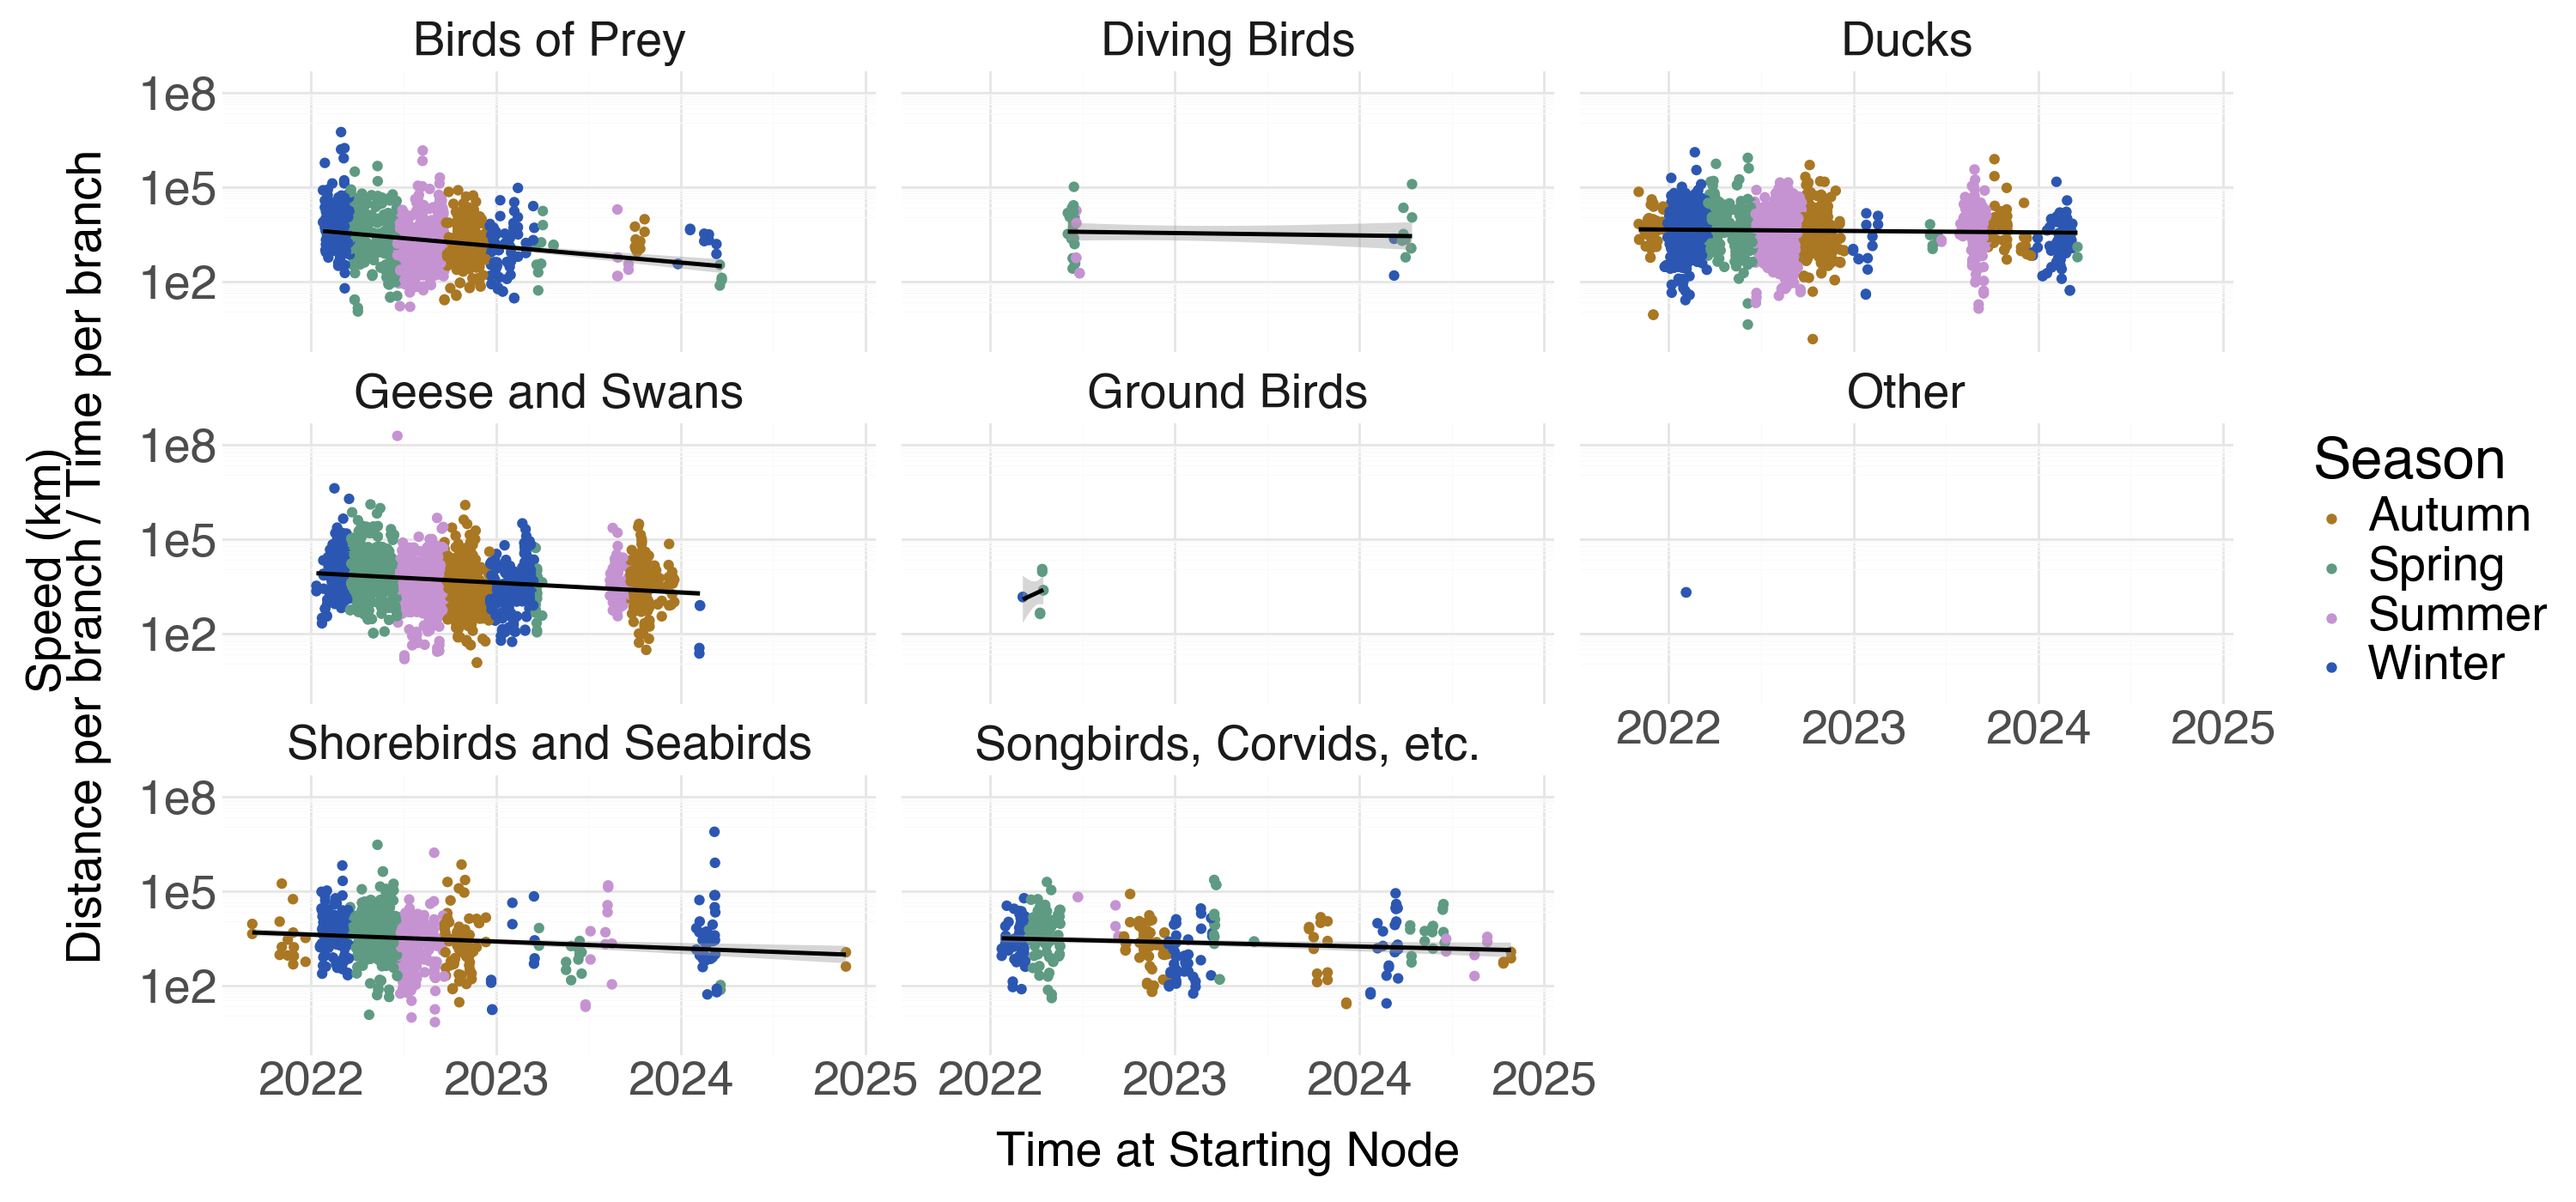

In [15]:
speed_over_time = (
    ggplot(mcc_metadata, aes(x = "startYear", y = "speed", color = "season"))
    + geom_point()
    # + geom_smooth(data = mcc_metadata, aes(x = "startYear", y = "speed", color = "startHost"), method='loess', span=0.4)
    + geom_smooth(mcc_metadata, aes(x = "startYear", y = "speed"), color = "black", span = 0.4)
    + facet_wrap("startHost", labeller = host_labels)
    + scale_y_log10()
    + labs(x = "Time at Starting Node", y = "Speed (km) \n Distance per branch / Time per branch", color = "Season")
    + scale_color_manual(season_colors, labels = {"autumn":"Autumn", "spring":"Spring", "winter":"Winter", "summer":"Summer"})
    + theme_minimal()
    + theme(figure_size = (15,7), legend_text=element_text(size=20), axis_title_x = element_text(size = 20), 
            axis_title_y = element_text(size = 20), text=element_text(size=20), axis_text_x = element_text(rotation = 0),
           legend_title = element_text(size = 24))
)

speed_over_time.show()

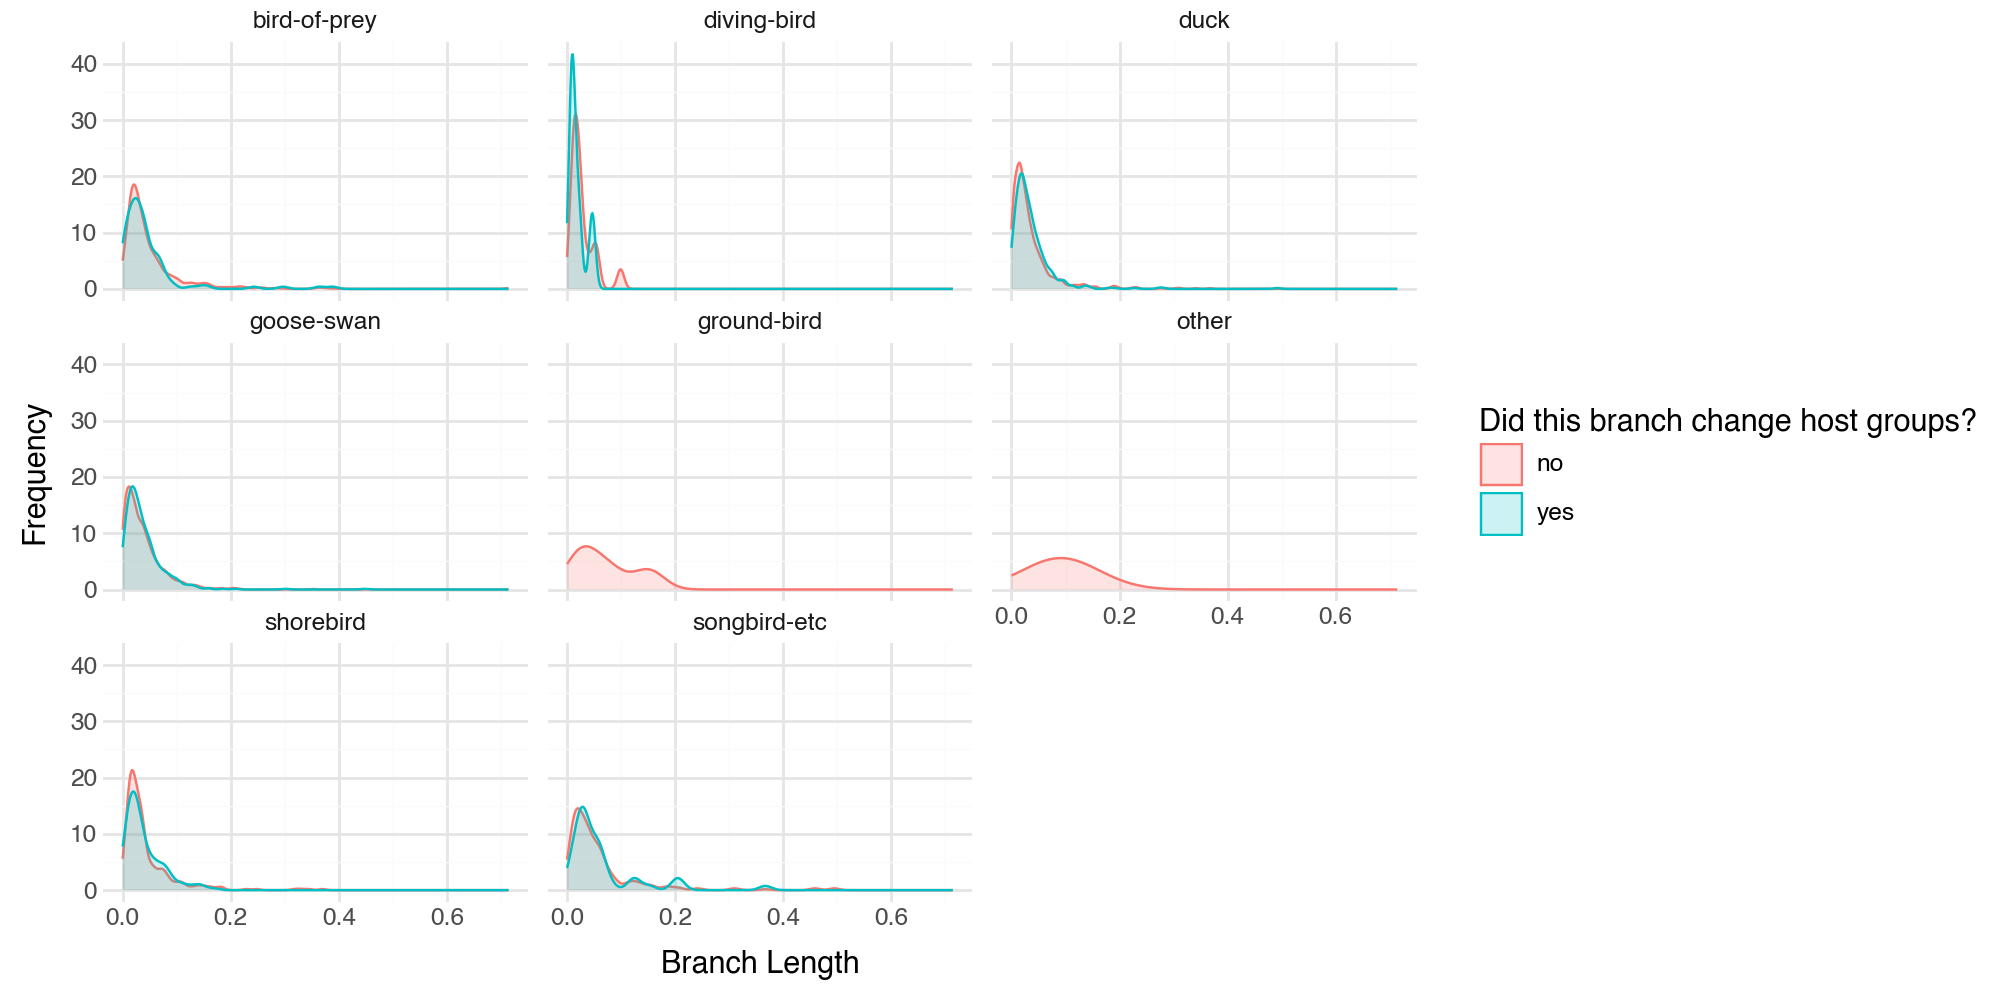

In [22]:
branch_length_transitions = (
    ggplot(mcc_metadata, aes(x = "length", color = "changeHost", fill = "changeHost"))
    + geom_density(alpha = 0.2)
    + labs(x = "Branch Length", y = "Frequency", color = "Did this branch change host groups?", fill = "Did this branch change host groups?")
    + facet_wrap("startHost")
    + theme_minimal()
    + theme(figure_size = (10, 5))
)

branch_length_transitions.show()

In [21]:
def decimal_year_to_datetime(decimal_year):
    year = int(decimal_year)
    remainder = decimal_year - year

    start = datetime(year, 1, 1)
    end = datetime(year + 1, 1, 1)

    return (start + timedelta(seconds=remainder * (end - start).total_seconds())).date()

In [22]:
def extract_month_index(dictionary):

    date_list = []

    for i in dictionary.values():
        i["startYear_datetime"] = i["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
        i["endYear_datetime"] = i["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object
        start = min(i["startYear_datetime"])
        end = max(i["endYear_datetime"])
        months = pd.date_range(start = start, end = end, freq = "MS")
        for month in months:
            month_date = month.date()
            if month_date in date_list:
                pass
            else:
                date_list.append(month_date)

    date_list_sorted = sorted(date_list)

    return(date_list_sorted)

In [23]:
# Function: to count the cumulative transitions from a trait, either across the posterior or for an MCC tree
# ChatGPT helped with refinement, especially for the posterior distribution section
def count_transitions(metadata, TRAIT, trait_list):

    if isinstance(metadata, dict): # If you are calculating from a dictionary of dataframes

        count = 1 # Start counting dataframes
        
        posterior_transitions_dict = {} # Initialize the dictionary for all hosts
        
        date_list = extract_month_index(metadata) # This provides a list of month start dates across the entire posterior

        for trait in trait_list: # Can change this depending on the traits
    
            posterior_transitions_dict[trait] = {} # Make an entry per host
            
            trait_dfs = [] # Make a list for all the dataframes

            for df in metadata.values(): # Iterate over each dataframe
        
                trans_per_df = {}
            
                df["startYear_datetime"] = df["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
                df["endYear_datetime"] = df["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object
            
                mask1 = (df[f"start{TRAIT}"] == trait) # In this instance, we want all instances of changes away from that trait as well
                df_trait = df[mask1]
                change_counts = 0
                counted_branches = set() # ChatGPT suggested this, to ensure that transitions are only counted once
        
                for month in date_list: # For each month of the dataframe
                    trans_per_df[month] = {}
                    
                    mask2 = ((df_trait["startYear_datetime"] <= month) & (df_trait["endYear_datetime"] > month)) # all branches that start before or at the month start and end after the month start
                    trait_monthly_branches = df_trait[mask2]
                    
                    new_changes_df = trait_monthly_branches[(trait_monthly_branches[f"change{TRAIT}"] == "yes") & (~trait_monthly_branches["branch_id"].isin(counted_branches))] # ChatGPT suggested this, to ensure that transitions are only counted once

                    new_ids = set(new_changes_df["branch_id"]) # ChatGPT added this to update the branches that have been seen
                    counted_branches.update(new_ids) # ChatGPT added this to update the branches that have been seen
                    
                    change_counts += len(new_ids) # Update the change counts to get a cumulative count

                    trans_per_df[month] = change_counts 
        
                trans_df = pd.DataFrame.from_dict(trans_per_df, orient = "index").reset_index()
                trans_df.columns = ["month", f"tree{count}_transitions"]
                trans_df[f"from_{TRAIT}"] = trait
        
                trait_dfs.append(trans_df) # Append all dataframes for that trait in a list
            
                count += 1

            per_trait_posterior = pd.concat((df.set_index(["month", f"from_{TRAIT}"]) for df in trait_dfs), axis = 1) # Concatenate all dataframes for each trait
        
            posterior_transitions_dict[trait] = per_trait_posterior # Save all in a dictionary, where each key is a trait value
    
        return(posterior_transitions_dict)

    elif isinstance(metadata, pd.DataFrame): # if you are calculating from just one dataframe
        
        metadata[f"change{TRAIT}_count"] = None
    
        for group, mini_df in metadata.groupby(f"start{TRAIT}"):
    
            change_count = 0
            mini_df = mini_df.sort_values("startYear")
        
            for idx, row in mini_df.iterrows():
                trait_change = row[f"change{TRAIT}"]
                if trait_change == "yes":
                   change_count += 1
                else:
                    pass
                    
                metadata.at[idx, f"change{TRAIT}_count"] = change_count
    
        metadata[f"change{TRAIT}_count"] = pd.to_numeric(metadata[f"change{TRAIT}_count"])
    
        return(metadata)

    else:
        print("Metadata of unknown type")

In [24]:
host_list = ["duck", "shorebird", "bird-of-prey", "goose-swan", "songbird-etc", "ground-bird", "diving-bird", "other"]
flyway_list = ["AtlanticFlyway", "CentralFlyway", "MississippiFlyway", "PacificFlyway"]

mcc_metadata_hostchange = count_transitions(mcc_metadata, "Host", host_list)
mcc_metadata_flywaychange = count_transitions(mcc_metadata, "Flyway", flyway_list)

In [19]:
host_list = ["duck", "shorebird", "bird-of-prey", "goose-swan", "songbird-etc", "ground-bird", "diving-bird", "other"]
host_transitions = count_transitions(metadata_dict, "Host", host_list)

flyway_list = ["AtlanticFlyway", "CentralFlyway", "MississippiFlyway", "PacificFlyway"]
flyway_transitions = count_transitions(metadata_dict, "Flyway", flyway_list)

In [20]:
def compute_hdi(metadata, PROB):

    if isinstance(metadata, dict):

        all_dfs = []
        
        for i in metadata.values():
            
            hdi_rows = i.apply(lambda row: az.hdi(row.values, hdi_prob = PROB), axis=1)
            hdi_series = hdi_rows.apply(pd.Series)
            hdi_series.columns = ["lower", "upper"]

            hdi_series["median"] = i.median(axis = 1)

            # print(hdi_series)

            all_dfs.append(hdi_series)

        concatenated = pd.concat(all_dfs)
        concatenated_reindexed = concatenated.reset_index()
        # print(concatenated_reindexed)

    return(concatenated_reindexed)

In [21]:
hdi_host_trans = compute_hdi(host_transitions, 0.95)
hdi_flyway_trans = compute_hdi(flyway_transitions, 0.95)

hdi_host_trans = hdi_host_trans.sort_values(by=["from_Host", "month"])
hdi_flyway_trans = hdi_flyway_trans.sort_values(by=["from_Flyway", "month"])

In [37]:
def select_date_labels(df, date_column):
    df[date_column] = pd.to_datetime(df[date_column])
    all_dates = df[date_column]
    date_labels = [d.strftime("%Y-%m") if d.month in [3, 6, 9, 12] else "" for d in all_dates]
    return(all_dates, date_labels)

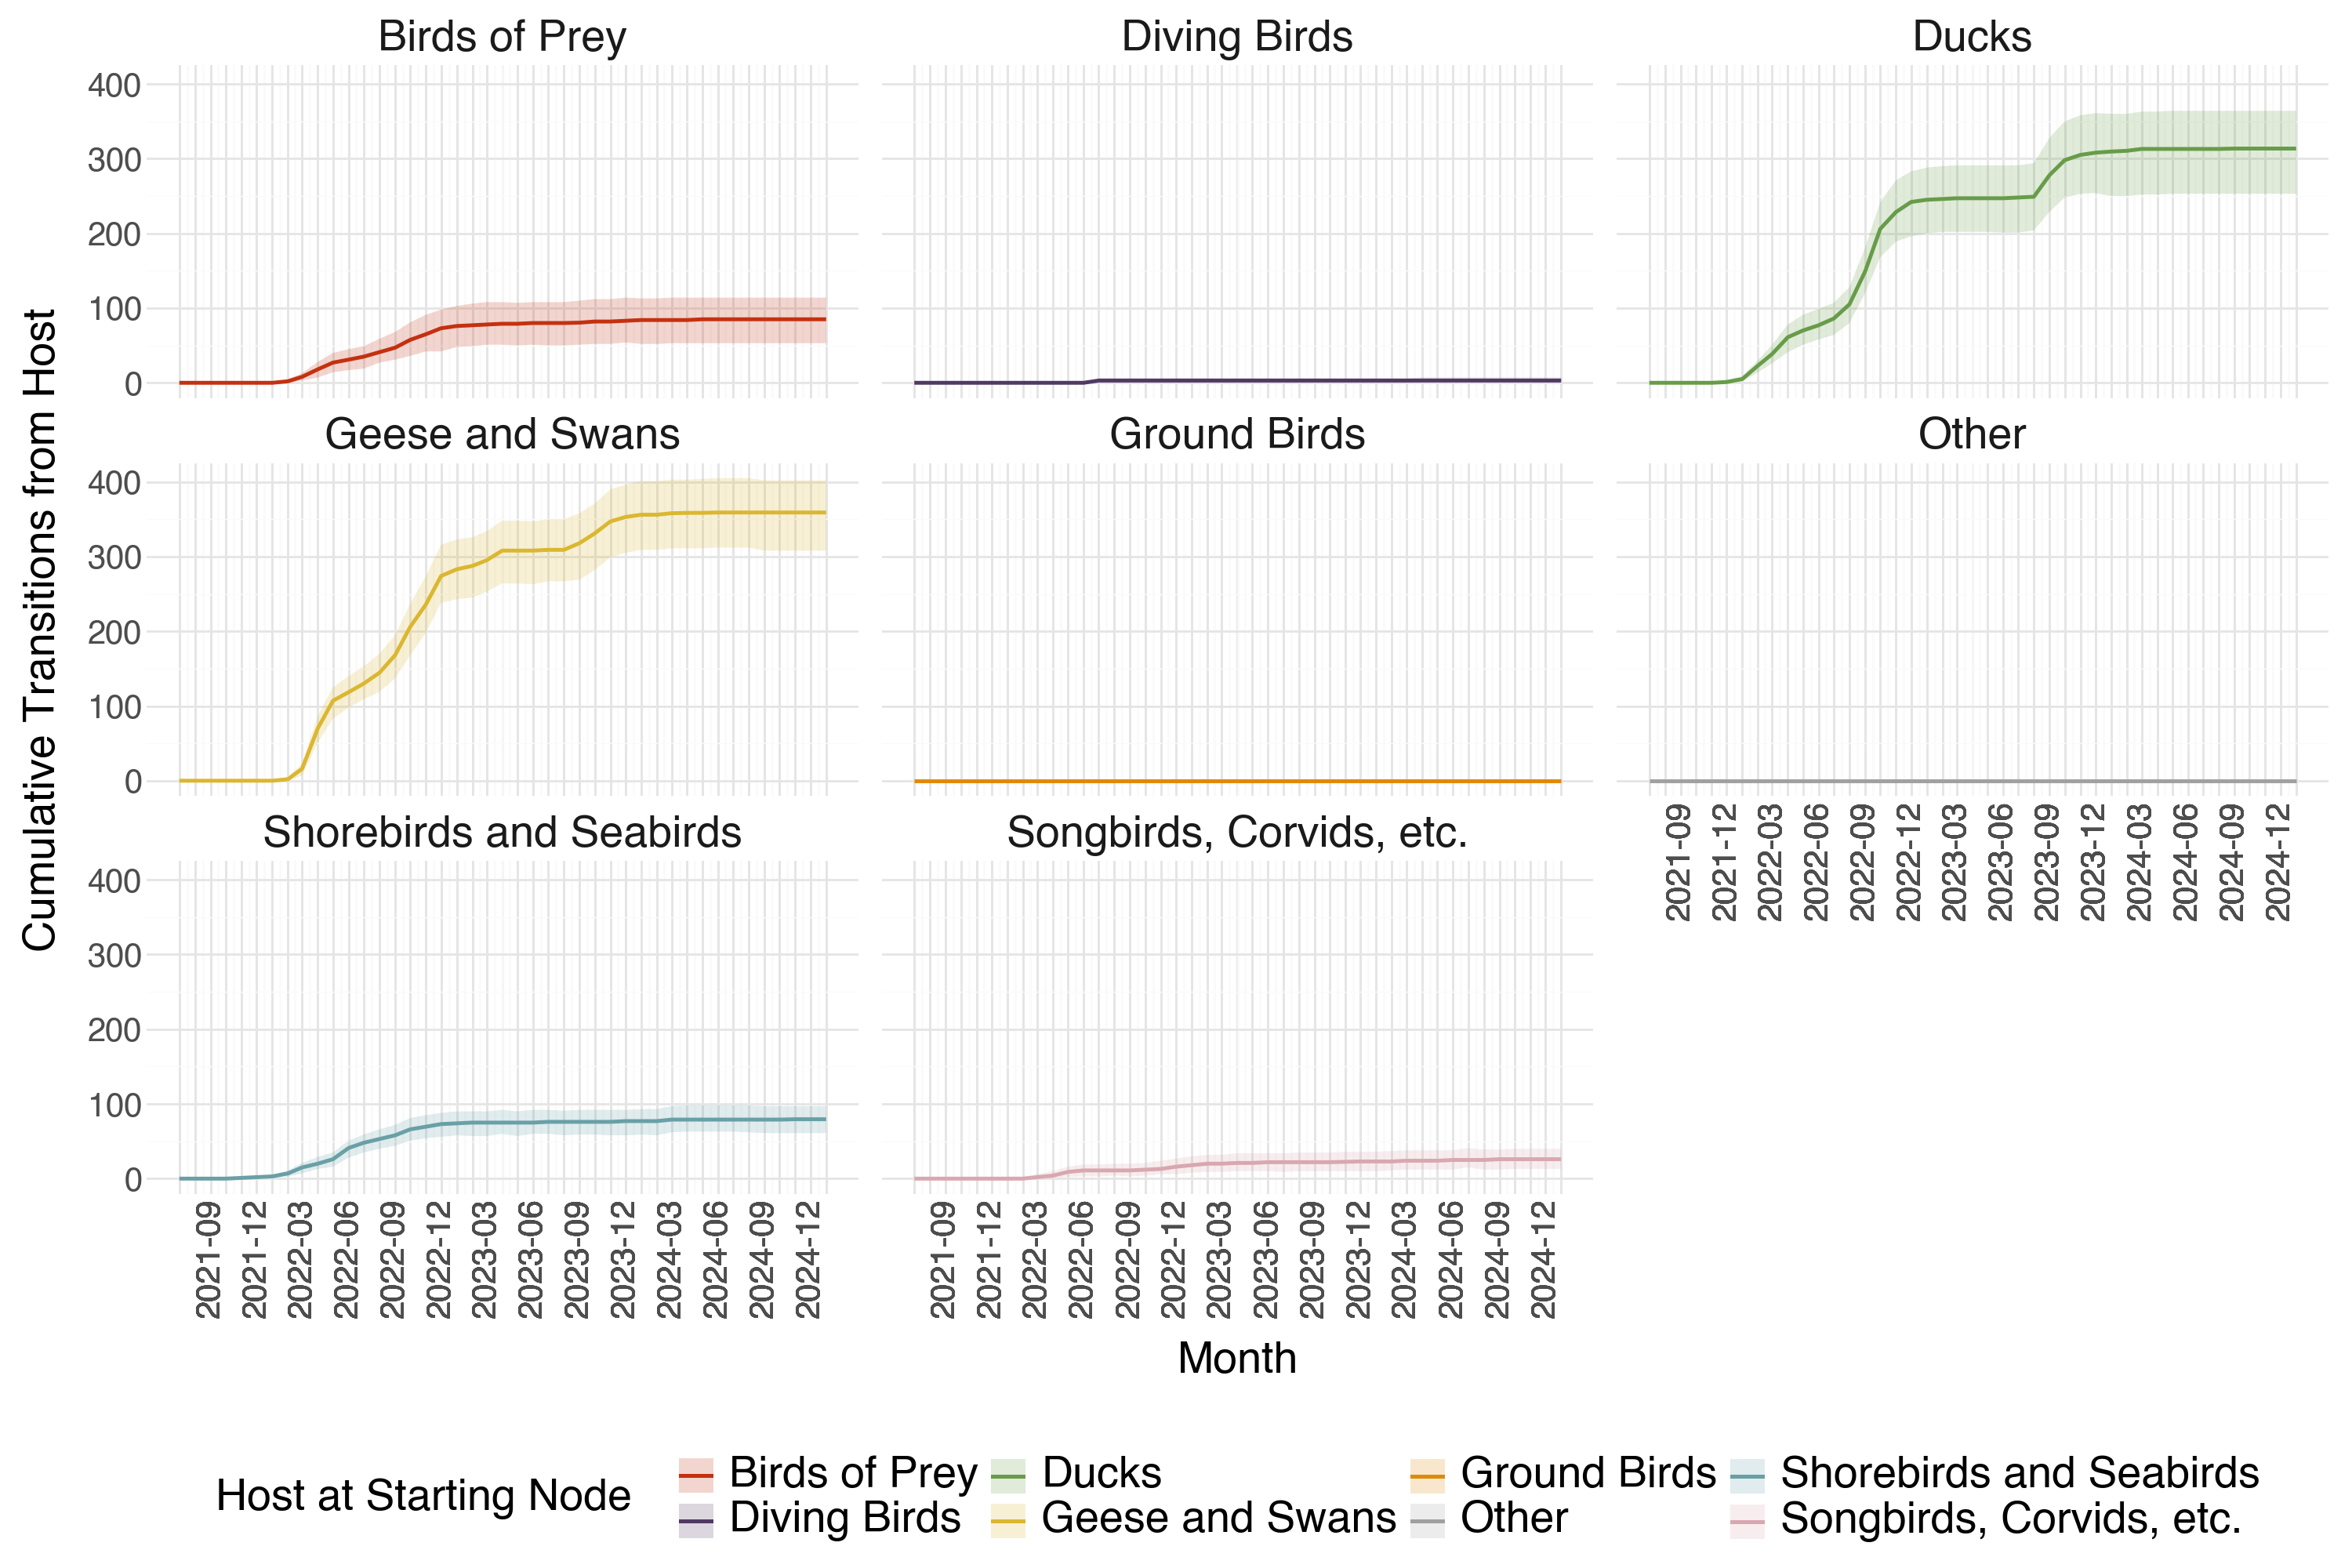

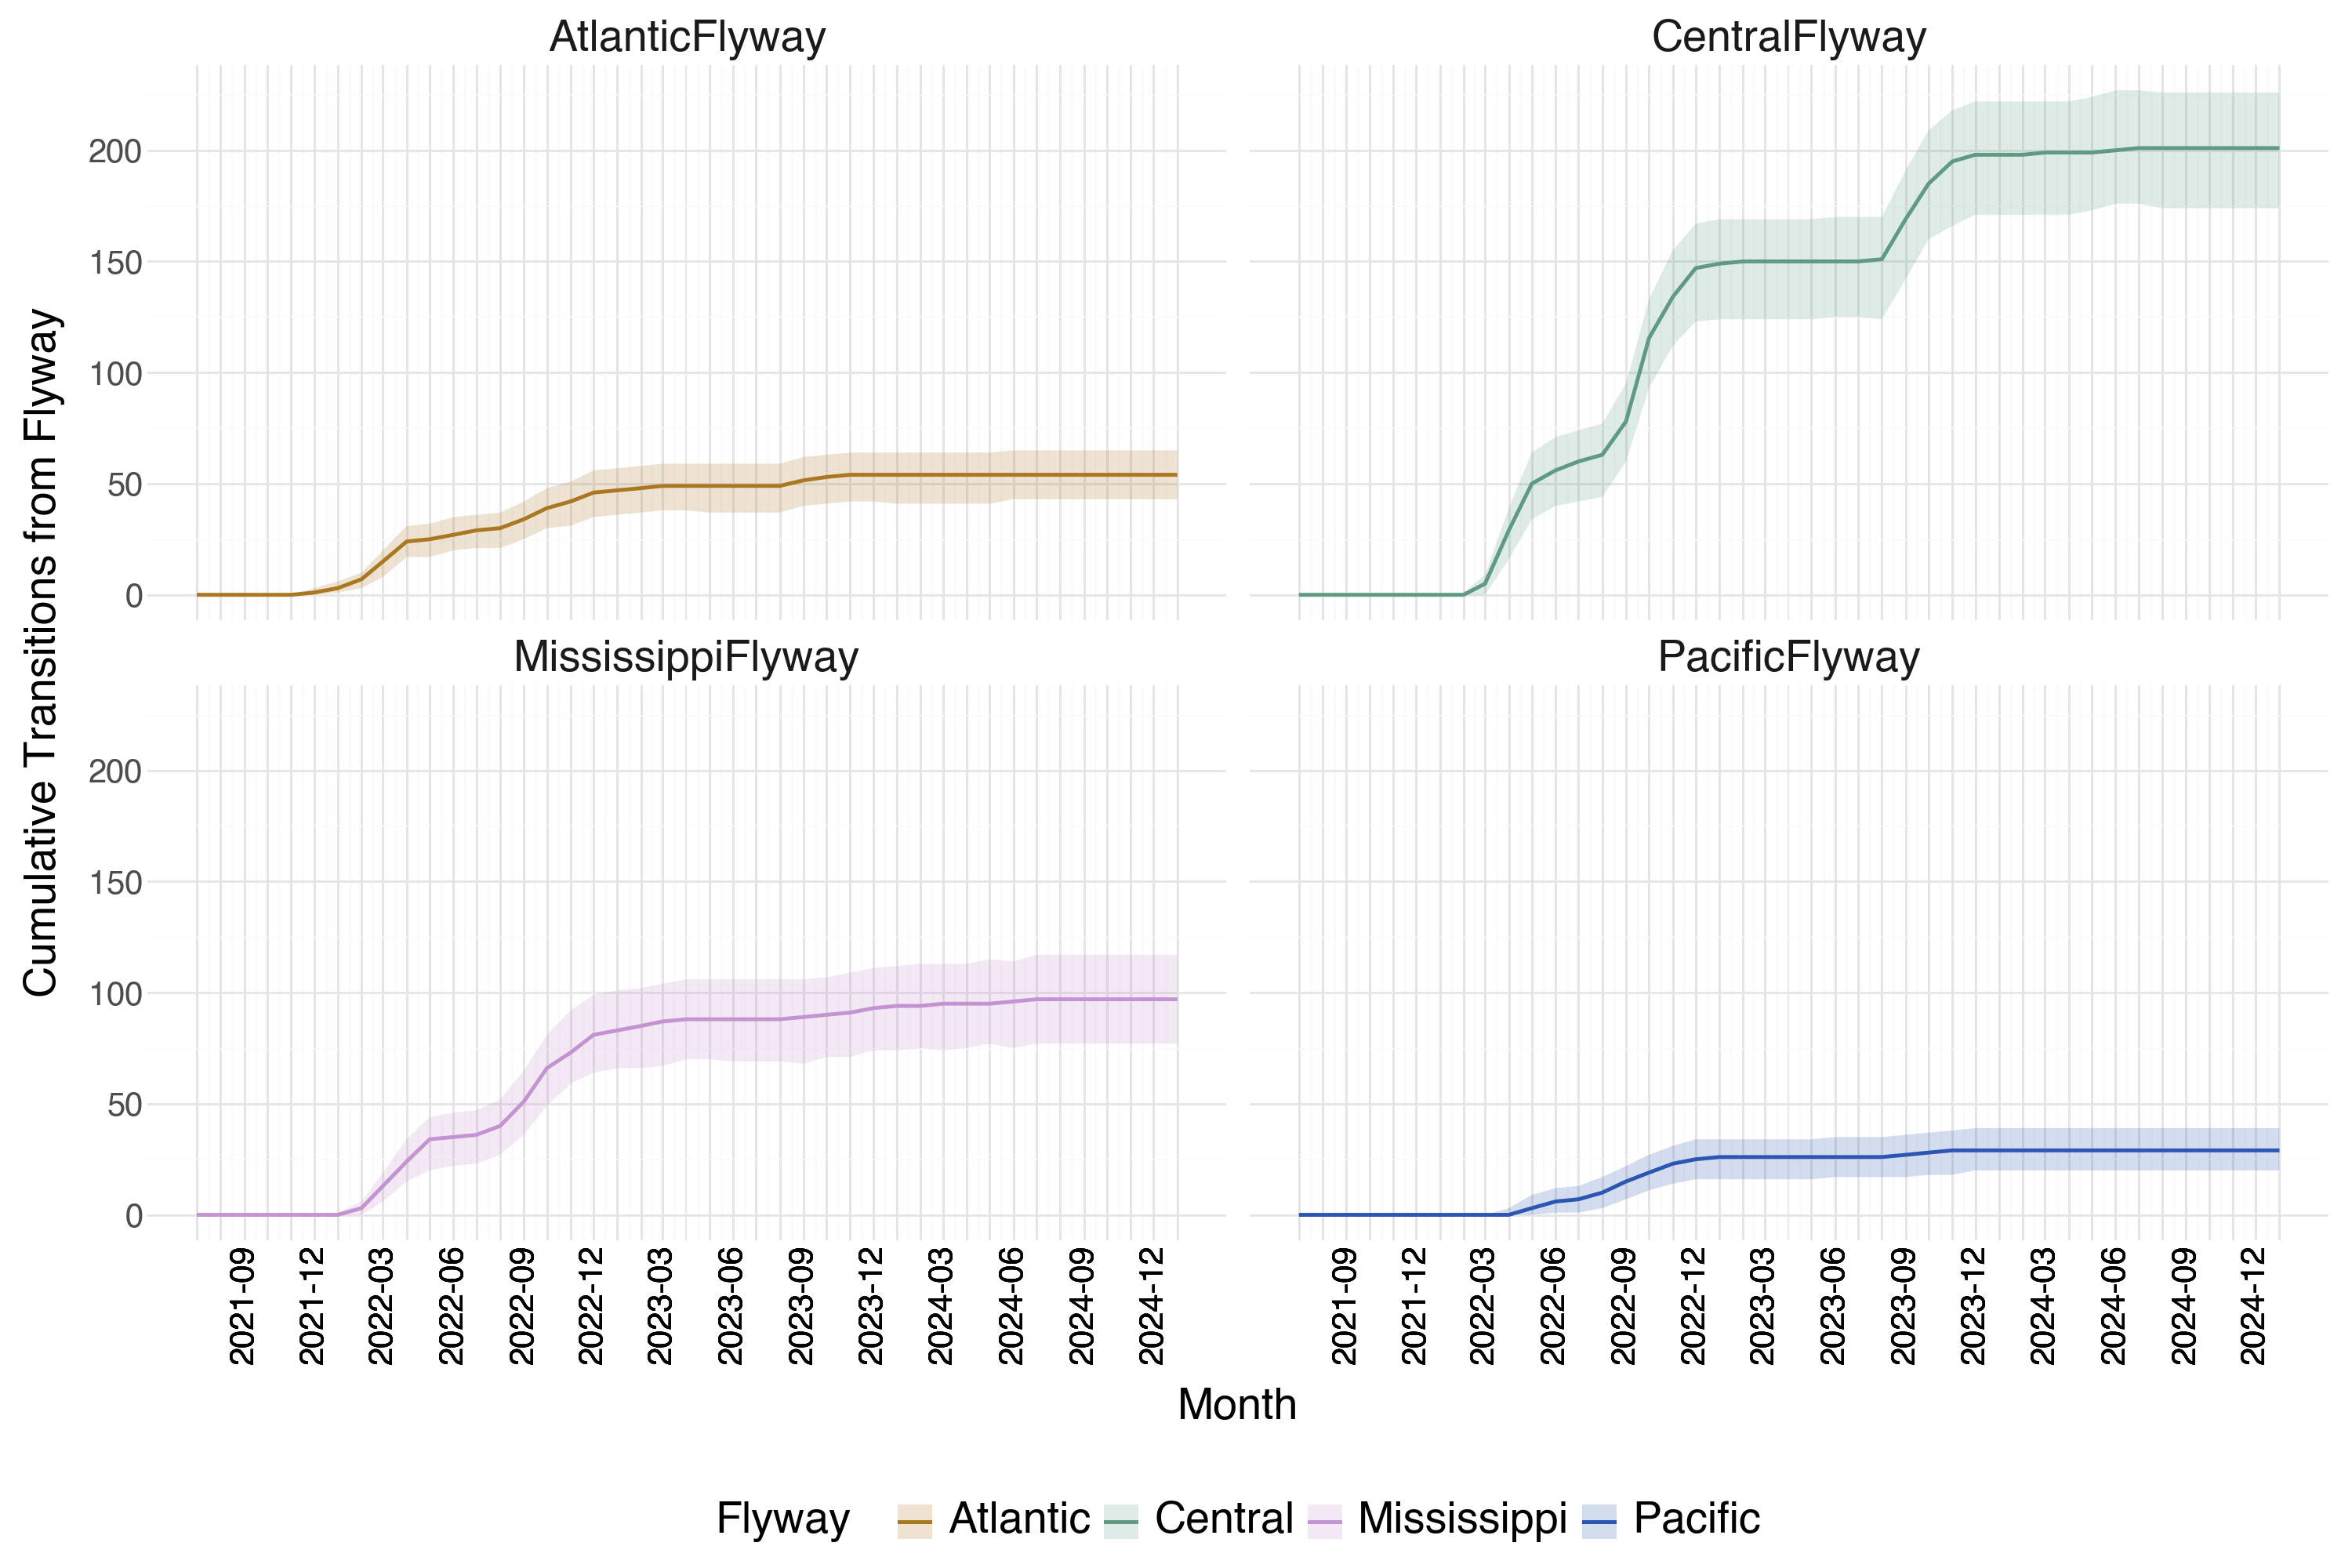

In [79]:
host_trans_dates, host_trans_date_labels = select_date_labels(hdi_host_trans, "month")
fly_trans_dates, fly_trans_date_labels = select_date_labels(hdi_flyway_trans, "month")

host_changes = (
    ggplot(hdi_host_trans, aes(x = "month", y = "median", color = "from_Host", group = "from_Host"))
    + geom_line(size = 1)
    + geom_ribbon(aes(x = "month", ymin = "lower", ymax = "upper", fill = "from_Host", group = "from_Host"), color = None, alpha = 0.2)
    + facet_wrap("from_Host", labeller = host_labels)
    + labs(x = "Month", y = "Cumulative Transitions from Host", color = "Host at Starting Node", fill = "Host at Starting Node")
    + scale_color_manual(host_colors, labels = host_labels)
    + scale_fill_manual(host_colors, labels = host_labels)
    + scale_x_datetime(breaks = host_trans_dates, labels = host_trans_date_labels) # This line allows me to piack and choose which dates are shown as labels
    + theme_minimal()
    + theme(figure_size = (15,10), legend_text=element_text(size=20), axis_title_x = element_text(size = 20), text=element_text(size=20),
            axis_title_y = element_text(size = 20), axis_text_y = element_text(size = 15), axis_text_x = element_text(size = 15, rotation = 90))
    + theme(legend_position = "bottom", legend_direction = "horizontal")
)

flyway_changes = (
    ggplot(hdi_flyway_trans, aes(x = "month", y = "median", color = "from_Flyway", group = "from_Flyway"))
    + geom_line(size = 1)
    + geom_ribbon(aes(x = "month", ymin = "lower", ymax = "upper", fill = "from_Flyway", group = "from_Flyway"), color = None, alpha = 0.2)
    + facet_wrap("from_Flyway")
    + labs(x = "Month", y = "Cumulative Transitions from Flyway", color = "Flyway", fill = "Flyway")
    + scale_fill_manual(values = {"AtlanticFlyway":"#AA7722", "PacificFlyway":"#2B57B3", "CentralFlyway":"#5E9B82", "MississippiFlyway":"#C593D1"}, 
                         labels = {"AtlanticFlyway":"Atlantic", "PacificFlyway":"Pacific", "CentralFlyway":"Central", "MississippiFlyway":"Mississippi"})
    + scale_color_manual(values = {"AtlanticFlyway":"#AA7722", "PacificFlyway":"#2B57B3", "CentralFlyway":"#5E9B82", "MississippiFlyway":"#C593D1"}, 
                         labels = {"AtlanticFlyway":"Atlantic", "PacificFlyway":"Pacific", "CentralFlyway":"Central", "MississippiFlyway":"Mississippi"})
    + scale_x_datetime(breaks = fly_trans_dates, labels = fly_trans_date_labels)
    + theme_minimal()
    + theme(figure_size = (15,10), legend_text=element_text(size=20), axis_title_x = element_text(size = 20), text=element_text(size=20),
            axis_title_y = element_text(size = 20), axis_text_y = element_text(size = 15), axis_text_x = element_text(size = 15, rotation = 90, color = "black"))
    + theme(legend_position = "bottom", legend_direction = "horizontal")
)

host_changes.show()
flyway_changes.show()

In [44]:
# These plots are for the MCC dataset

mcc_host_changes = (
    ggplot(mcc_metadata_hostchange, aes(x = "startYear", y = "changeHost_count", color = "startHost", group = 1))
    + geom_line(size = 1)
    + facet_wrap("startHost", labeller = host_labels)
    + labs(x = "Time at Starting Node", y = "Cumulative Transitions from Host", color = "Host at Starting Node")
    + scale_color_manual(host_colors, labels = host_labels)
    + theme_minimal()
    + theme(figure_size = (15,10), legend_text=element_text(size=24), axis_title_x = element_text(size = 20), 
            axis_title_y = element_text(size = 20), text=element_text(size=20), axis_text_x = element_text(rotation = 60))
)

mcc_flyway_changes = (
    ggplot(mcc_metadata_flywaychange, aes(x = "startYear", y = "changeFlyway_count", color = "startFlyway", group = 1))
    + geom_line(size = 1)
    + facet_wrap("startFlyway")
    + labs(x = "Time at Starting Node", y = "Cumulative Transitions from Flyway", color = "Flyway at Starting Node")
    + scale_color_manual(values = {"AtlanticFlyway":"#AA7722", "PacificFlyway":"#2B57B3", "CentralFlyway":"#5E9B82", "MississippiFlyway":"#C593D1"}, 
                         labels = {"AtlanticFlyway":"Atlantic", "PacificFlyway":"Pacific", "CentralFlyway":"Central", "MississippiFlyway":"Mississippi"})
    + theme_minimal()
    + theme(figure_size = (10,5), legend_text=element_text(size=24), axis_title_x = element_text(size = 20), 
            axis_title_y = element_text(size = 20), text=element_text(size=20), axis_text_x = element_text(rotation = 60))
)



# mcc_host_changes.show()
# mcc_flyway_changes.show()

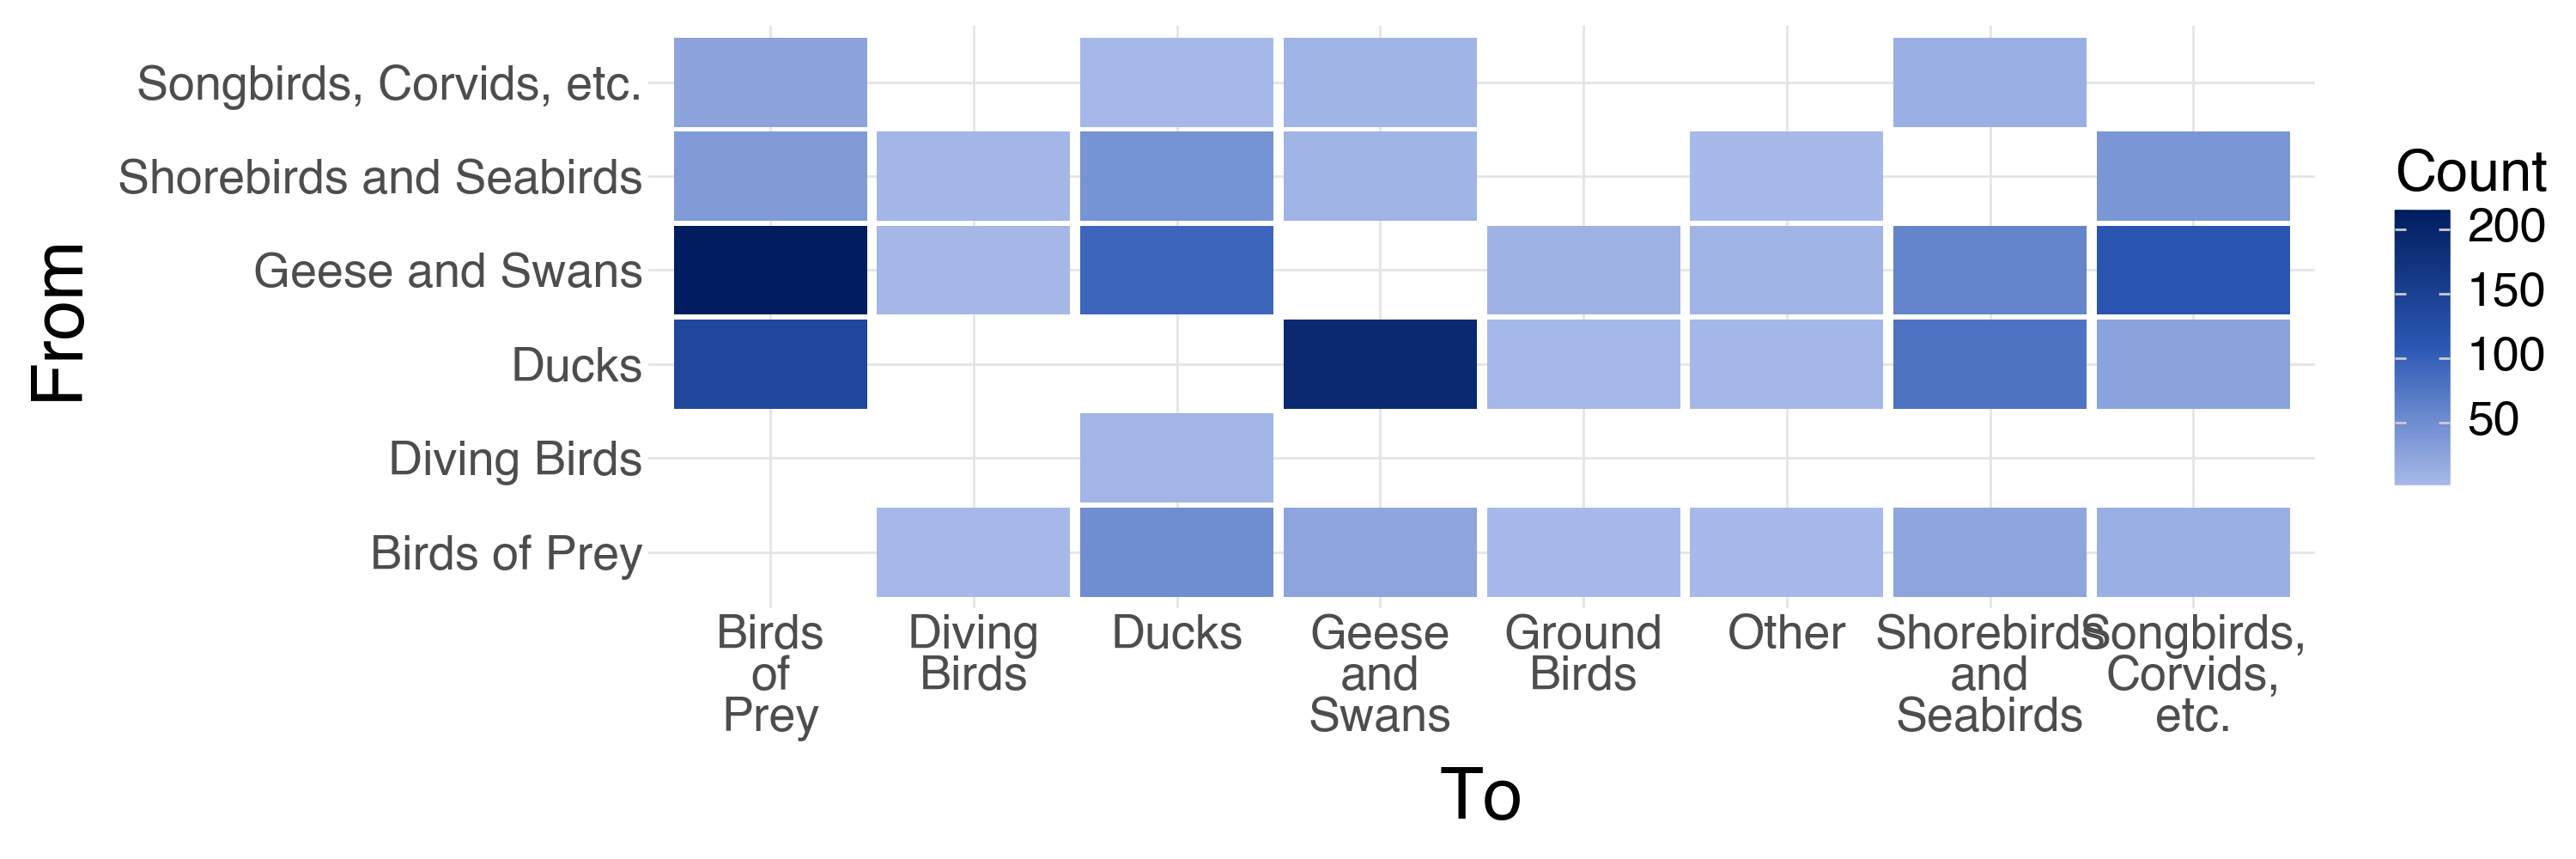

In [27]:
just_changes = mcc_metadata_hostchange.loc[mcc_metadata_hostchange["changeHost"] == "yes"]

counts = just_changes.groupby(["startHost", "endHost"]).size().reset_index().rename({0:"freq"}, axis = 1)

x_axis_labels = {"bird-of-prey":"Birds\nof\nPrey",
                 "duck":"Ducks",
                 "goose-swan": "Geese\nand\nSwans",
                 "shorebird":"Shorebirds\nand\nSeabirds",
                 "songbird-etc":"Songbirds,\nCorvids,\netc.",
                 "ground-bird":"Ground\nBirds",
                 "diving-bird":"Diving\nBirds",
                 "other":"Other"
                }

mcc_host_tofrom = (
    ggplot(counts, aes(x = "endHost", y = "startHost", fill = "freq"))
    + geom_tile(aes(width=0.95, height=0.95))
    # + geom_text(aes(label="freq"), size=13)
    + scale_fill_gradient2(low="#A7B9E8",mid="#2B57B3",high="#001B5C",midpoint=110)
    + labs(x = "To", y = "From", fill = "Count")
    + scale_x_discrete(labels=x_axis_labels)
    + scale_y_discrete(labels=host_labels)
    + theme_minimal()
    + theme(figure_size = (15, 5), legend_title=element_text(size = 24), legend_text=element_text(size=20), axis_title_x = element_text(size = 30), 
            axis_title_y = element_text(size = 30), axis_text_x=element_text(size=20, rotation = 0), axis_text_y=element_text(size=20))
)

mcc_host_tofrom.show()

In [51]:
# Function: calculates the average weighted diffusion coefficient from either the posterior distirbution or an MCC tree
def calculate_avg_wdc(metadata):

    if isinstance(metadata, dict): # If you are calculating from a dictionary of dataframes
        posterior_wdc = {}
        df_count = 1
        
        for df in metadata.values():
            if df_count <= 10: 
                
                posterior_wdc[df_count] = {}
                
                # Measure [average] WDC by host
                for i in set(df["startHost"]):
                    posterior_wdc[df_count][i] = {}
                    
                    df_host = df.loc[(df["startHost"] == i) & (df["endHost"] == i)] # Filter to just branches with a single host (no transitions)
        
                    post_wdc_host = (df_host["dist_branch"] ** 2).sum() / (4 * (df_host["time"] * 365)).sum() # Calculate time in days, not years
        
                    posterior_wdc[df_count][i] = post_wdc_host # Save the WDC of each host to a dictionary
        
                    # if i == "other":
                    #     print(df_count, i, df_host["dist_branch"].to_list())
                    #     print(df_host)
                
                df_count += 1 # Increase the dataframe count and move to the next datafrome in the distribution

        posterior_wdc_df = pd.DataFrame(posterior_wdc).fillna(0)
        posterior_wdc_df_long = (posterior_wdc_df.reset_index().rename(columns={'index': 'host'}).melt(id_vars='host',var_name='tree',value_name='wdc'))
    
        return(posterior_wdc_df_long)

    elif isinstance(metadata, pd.DataFrame): # if you are calculating from just one dataframe
        mcc_wdc = {}

        for i in set(metadata["startHost"]): # Measure WDC by host

            mcc_wdc[i] = {}
            
            metadata_host = metadata.loc[(metadata["startHost"] == i) & (metadata["endHost"] == i)] # Filter to just branches with a single host (no transitions)

            mcc_wdc_host = (metadata_host["dist_branch"] ** 2).sum() / (4 * (metadata_host["time"] * 365)).sum() # Calculate time in days, not years
            # mcc_wdc_host = (metadata_host["dist_branch"] ** 2).sum() / (4 * metadata_host["time"]).sum() # Calculate time iyears


            mcc_wdc[i] = mcc_wdc_host
            # print("mcc", i, len(metadata_host), mcc_wdc_host)

        mcc_wdc_df = pd.DataFrame.from_dict(mcc_wdc, orient="index", columns=["wdc"])
        
        return(mcc_wdc_df)

    else:
        print("Metadata of unknown type")

In [52]:
wdc_mcc = calculate_avg_wdc(mcc_metadata)
wdc_distrib = calculate_avg_wdc(metadata_dict)

In [53]:
# I want to see what the plot would look like as a bar plot with error bars, rather than a density plot

hdi_hosts = wdc_distrib.groupby("host")["wdc"].apply(lambda col: az.hdi(col.values, hdi_prob=0.95))

wdc_distrib_error = hdi_hosts.apply(pd.Series)
wdc_distrib_error.columns = ["lower", "upper"]

wdc_distrib_error["median"] = wdc_distrib.groupby("host")["wdc"].median()
wdc_distrib_error["mean"] = wdc_distrib.groupby("host")["wdc"].mean()
# wdc_distrib_error["mode"] = wdc_distrib.groupby("host")["wdc"].mode()

wdc_distrib_error = wdc_distrib_error.reset_index()

In [60]:
print(wdc_distrib_error)

# For presentations, remove "other" and NaN
presentation_hosts = ["bird-of-prey", "diving-bird", "duck", "goose-swan", "ground-bird", "shorebird", "songbird-etc"]
wdc_distrib_error_present = wdc_distrib_error[wdc_distrib_error["host"].isin(presentation_hosts)]

           host        lower         upper       median         mean
0  bird-of-prey  1817.118598   2235.638122  2004.982699  2011.177764
1   diving-bird   200.884914   1453.947875   752.536717   774.632200
2          duck  4471.676171   5613.375764  4987.913368  5006.962734
3    goose-swan  3158.857830   4104.236358  3509.045542  3605.459063
4   ground-bird   375.533926   2086.966678   821.529529  1001.403423
5         other   132.165440  50088.649677  4179.527935  8677.282429
6     shorebird  1960.073724   3045.820452  2869.879487  2768.986469
7  songbird-etc  1555.630406   3720.284579  2015.968211  2275.462188


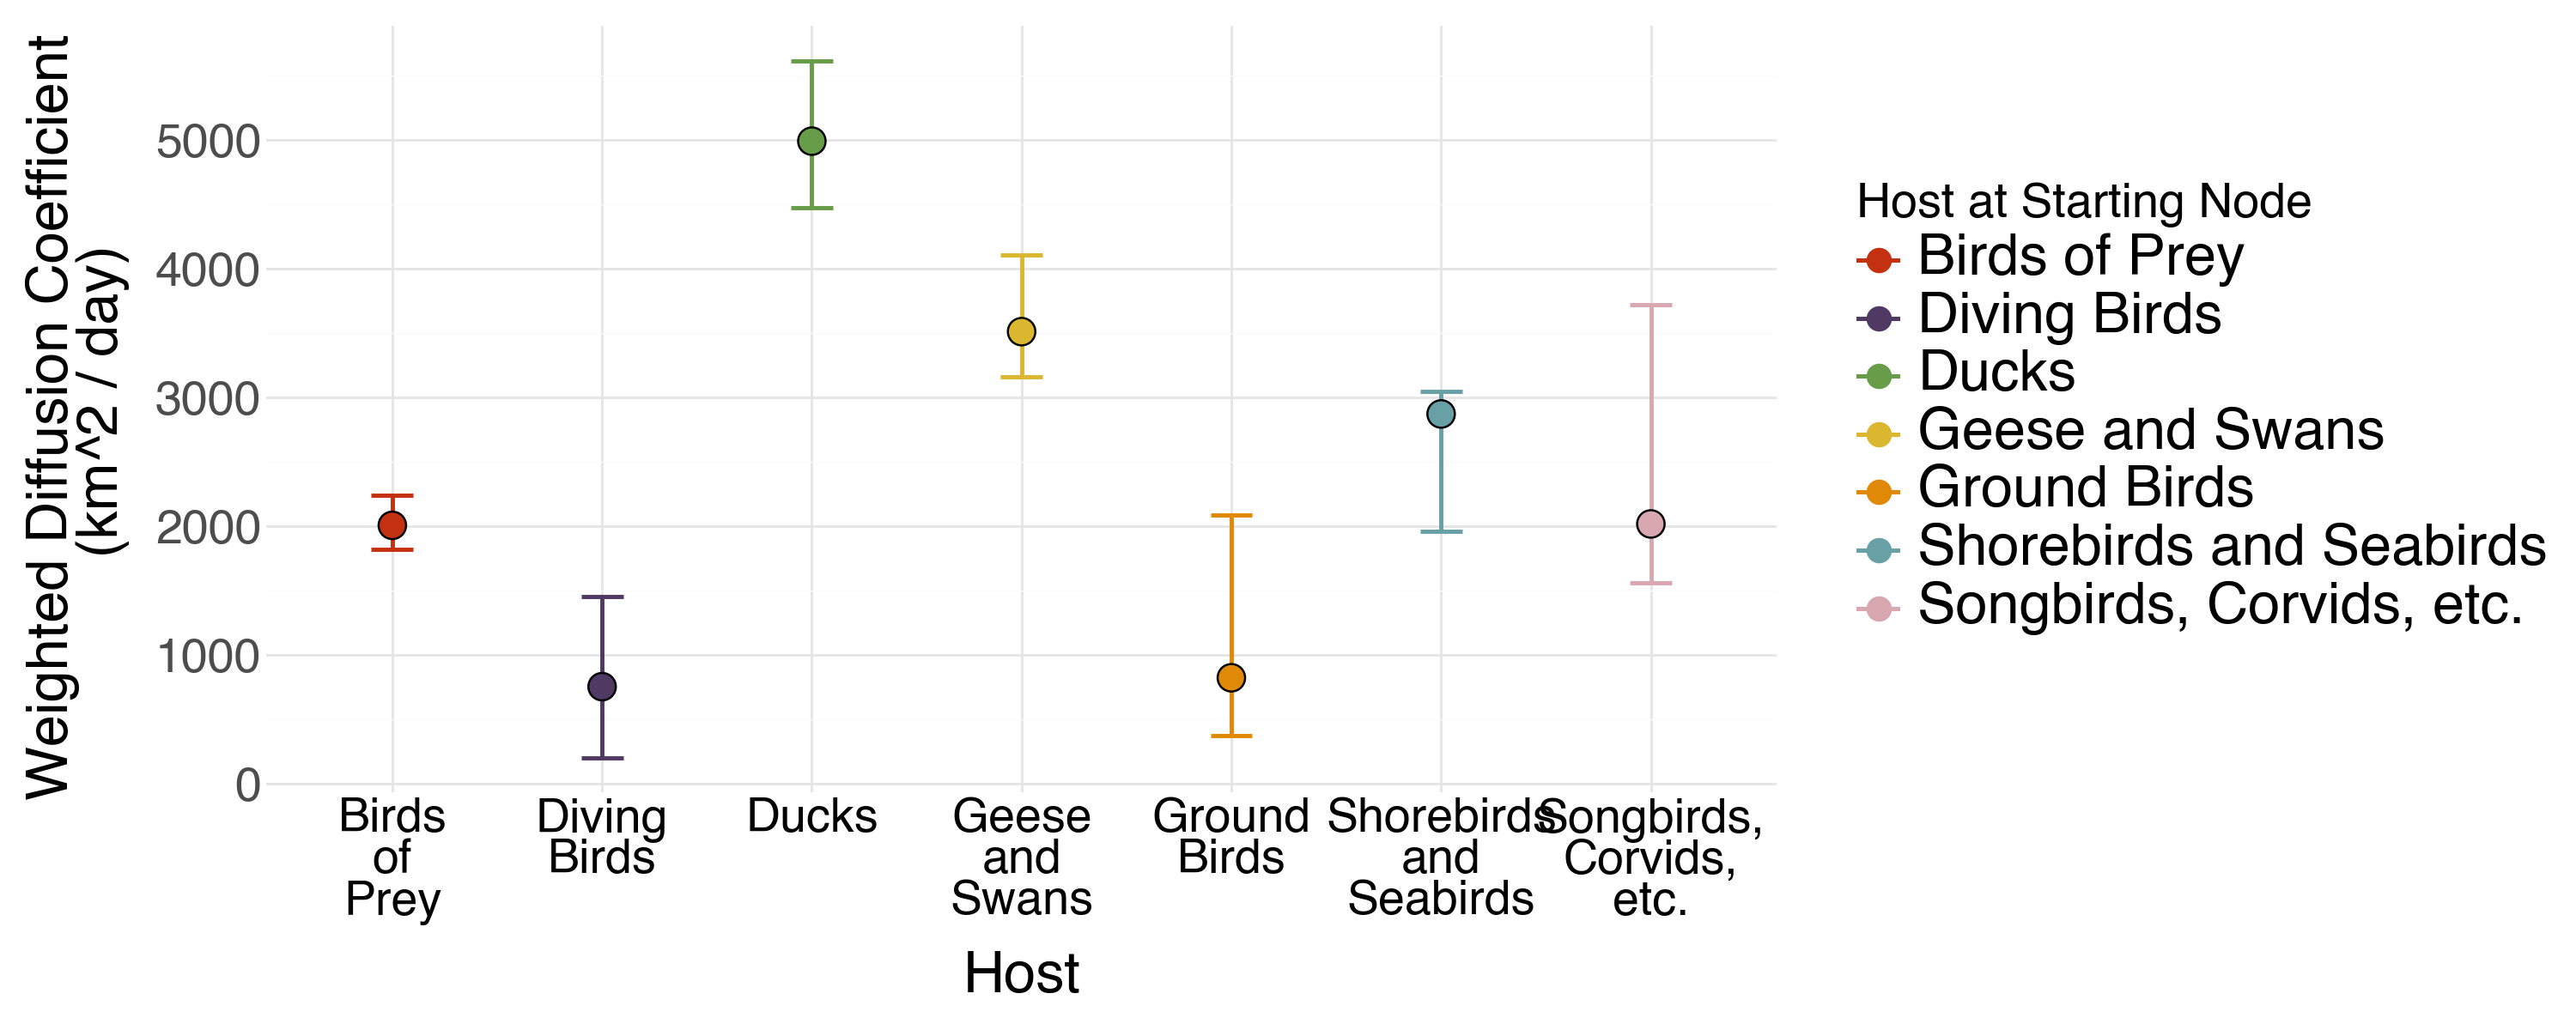

In [89]:
# wdc_per_host = (
#     ggplot(wdc_distrib, aes(x='wdc', color="host", fill="host"))
#     + geom_density(alpha=0.0, size = 2)
#     + labs(x='Weighted Diffusion Coefficient',y='Frequency', color = "Host at Starting Node", fill = "Host at Starting Node")
#     + scale_fill_manual(host_colors, labels = host_labels)
#     + scale_color_manual(host_colors, labels = host_labels)
#     + xlim(0.5, 5000)
#     # + scale_x_log10()
#     + theme_minimal()
#     + theme(figure_size = (10,5), legend_text=element_text(size=24), axis_title_x = element_text(size = 20), 
#             axis_title_y = element_text(size = 20), text=element_text(size=20))
# )

# I made this more specific labeller ONLY because I wanted to move things to new lines
x_axis_labels = {"bird-of-prey":"Birds\nof\nPrey",
                 "duck":"Ducks",
                 "goose-swan": "Geese\nand\nSwans",
                 "shorebird":"Shorebirds\nand\nSeabirds",
                 "songbird-etc":"Songbirds,\nCorvids,\netc.",
                 "ground-bird":"Ground\nBirds",
                 "diving-bird":"Diving\nBirds",
                 "other":"Other"
                }

wdc_per_host_2 = (
    ggplot()
    + geom_errorbar(wdc_distrib_error_present, aes(x = "host", ymin = "lower", ymax = "upper", color = "host"), width = 0.2, size = 1)
    + geom_point(wdc_distrib_error_present, aes(x = "host", y = "median"), size = 6, color = "black")
    + geom_point(wdc_distrib_error_present, aes(x = "host", y = "median", color = "host"), size = 5)
    + labs(x='Host',y='Weighted Diffusion Coefficient \n (km^2 / day)', color = "Host at Starting Node", fill = "Host at Starting Node")
    + scale_fill_manual(host_colors, labels = host_labels)
    + scale_color_manual(host_colors, labels = host_labels)
    + scale_x_discrete(labels = x_axis_labels) # This sets the labels on the x-axis
    + theme_minimal()
    + theme(figure_size = (15,6), legend_text=element_text(size=24), axis_title_x = element_text(size = 24), 
            axis_title_y = element_text(size = 24), text=element_text(size=20), axis_text_x = element_text(rotation = 0, color = "black"))
)

# wdc_per_host.show()
wdc_per_host_2.show()                     

In [71]:
# Function: calculates WDC over time

def calculate_monthly_wdc(metadata, TRAIT, trait_list):

    if isinstance(metadata, dict): # If you are calculating from a dictionary of dataframes
         
        posterior_wdc_dict = {} # Initialize the dictionary for all hosts
        
        date_list = extract_month_index(metadata) # This provides a list of month start dates across the entire posterior

        for trait in trait_list: # Can change this depending on the traits

            count = 1 # Start counting dataframes
    
            posterior_wdc_dict[trait] = {} # Make an entry per host
            
            trait_dfs = [] # Make a list for all the dataframes

            for df in metadata.values(): # Iterate over each dataframe

                wdc_per_df = {} # Initialize a dictionary for EACH TREE/DATAFRAME
            
                df["startYear_datetime"] = df["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
                df["endYear_datetime"] = df["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object
            
                mask1 = ((df[f"start{TRAIT}"] == trait) & (df[f"end{TRAIT}"] == trait)) # Limit to just the trait in question (calculate WDC just within that trait)
                df_trait = df[mask1]
        
                for month in date_list: # For each month of the dataframe
                    wdc_per_df[month] = {} # Entry in dictionary per month
                    
                    mask2 = ((df_trait["startYear_datetime"] <= month) & (df_trait["endYear_datetime"] > month)) # all branches that start before or at the month start and end after the month start
                    trait_monthly_branches = df_trait[mask2]
                    
                    if len(trait_monthly_branches) == 0: # Some months have 0 branches, which generates a NaN wonthly_wdc because you cannot divide by time
                        monthly_wdc = 0
                    else:
                        monthly_wdc = (trait_monthly_branches["dist_branch"] ** 2).sum() / (4 * (trait_monthly_branches["time"] * 365)).sum() # Calculate WDC per month with time in days, not years
                   
                    wdc_per_df[month] = monthly_wdc
        
                wdc_df = pd.DataFrame.from_dict(wdc_per_df, orient = "index").reset_index()
                wdc_df.columns = ["month", f"tree{count}_monthlywdc"]
                wdc_df[f"{TRAIT}"] = trait

        
                trait_dfs.append(wdc_df) # Save each dataframe to a different list for each trait
            
                count += 1
        
            per_trait_posterior = pd.concat((df.set_index(["month", f"{TRAIT}"]) for df in trait_dfs), axis = 1) # Concatenate all the dataframes within each list (within each trait)
        
            posterior_wdc_dict[trait] = per_trait_posterior

        return(posterior_wdc_dict)

    elif isinstance(metadata, pd.DataFrame): # if you are calculating from just one dataframe
        
        wdc_per_month = {} # An empty dictionary for WDC per month
        
        # Measure WDC per month
        metadata["startYear_datetime"] = metadata["startYear"].apply(decimal_year_to_datetime) # Turn startYear from a float into a datetime object
        metadata["endYear_datetime"] = metadata["endYear"].apply(decimal_year_to_datetime) # Turn endYear from a float into a datetime object

        start = min(metadata["startYear_datetime"])
        end = max(metadata["endYear_datetime"])
        # print(df["tipLabel"].loc[df["endYear"] == max(df["endYear"])])
        months = pd.date_range(start = start, end = end, freq = "MS")# make a list of months

        for host in set(metadata["startHost"]):
            host_df = metadata.loc[(metadata["startHost"] == host) & (metadata["endHost"] == host)]
            if len(host_df) > 2: # Come hosts may only have a couple of points, but I'm not sure what the limit should be
                wdc_per_month[host] = {}
                for month in months: 
                    month_date = month.date()
                    mask = ((host_df["startYear_datetime"] <= month) & (host_df["endYear_datetime"] > month)) # all branches that start before or at the month start and end after the month start
                    branches_in_month = host_df[mask] # Bin branches by month end
                    # branches_per_month_host = branches_in_month.loc[(branches_in_month["startHost"] == i) & (branches_in_month["endHost"] == i)]
                    monthly_host_wdc = (branches_in_month["dist_branch"] ** 2).sum() / (4 * (branches_in_month["time"] * 365)).sum() # Calculate WDC per month with time in days, not years
                    wdc_per_month[host][month_date] = 0 if pd.isna(monthly_host_wdc) else monthly_host_wdc # Fill the dictionary with the monthly WDC
            
        wdc_per_month_df = pd.DataFrame(wdc_per_month).reset_index().rename({"index":"Month"}, axis = 1) # Make a dataframe of WDC per month

        return(wdc_per_month_df)

    else:
        print("Metadata of unknown type")

In [72]:
trait_list = ["duck", "shorebird", "bird-of-prey", "goose-swan", "songbird-etc", "ground-bird", "diving-bird", "other"]

# monthly_df = calculate_monthly_wdc(mcc_metadata_updated, trait_list)
monthly_wdc = calculate_monthly_wdc(metadata_dict, "Host", trait_list)

In [73]:
# Compute HDI using the function from earlier

hdi_host_wdc = compute_hdi(monthly_wdc, 0.80)

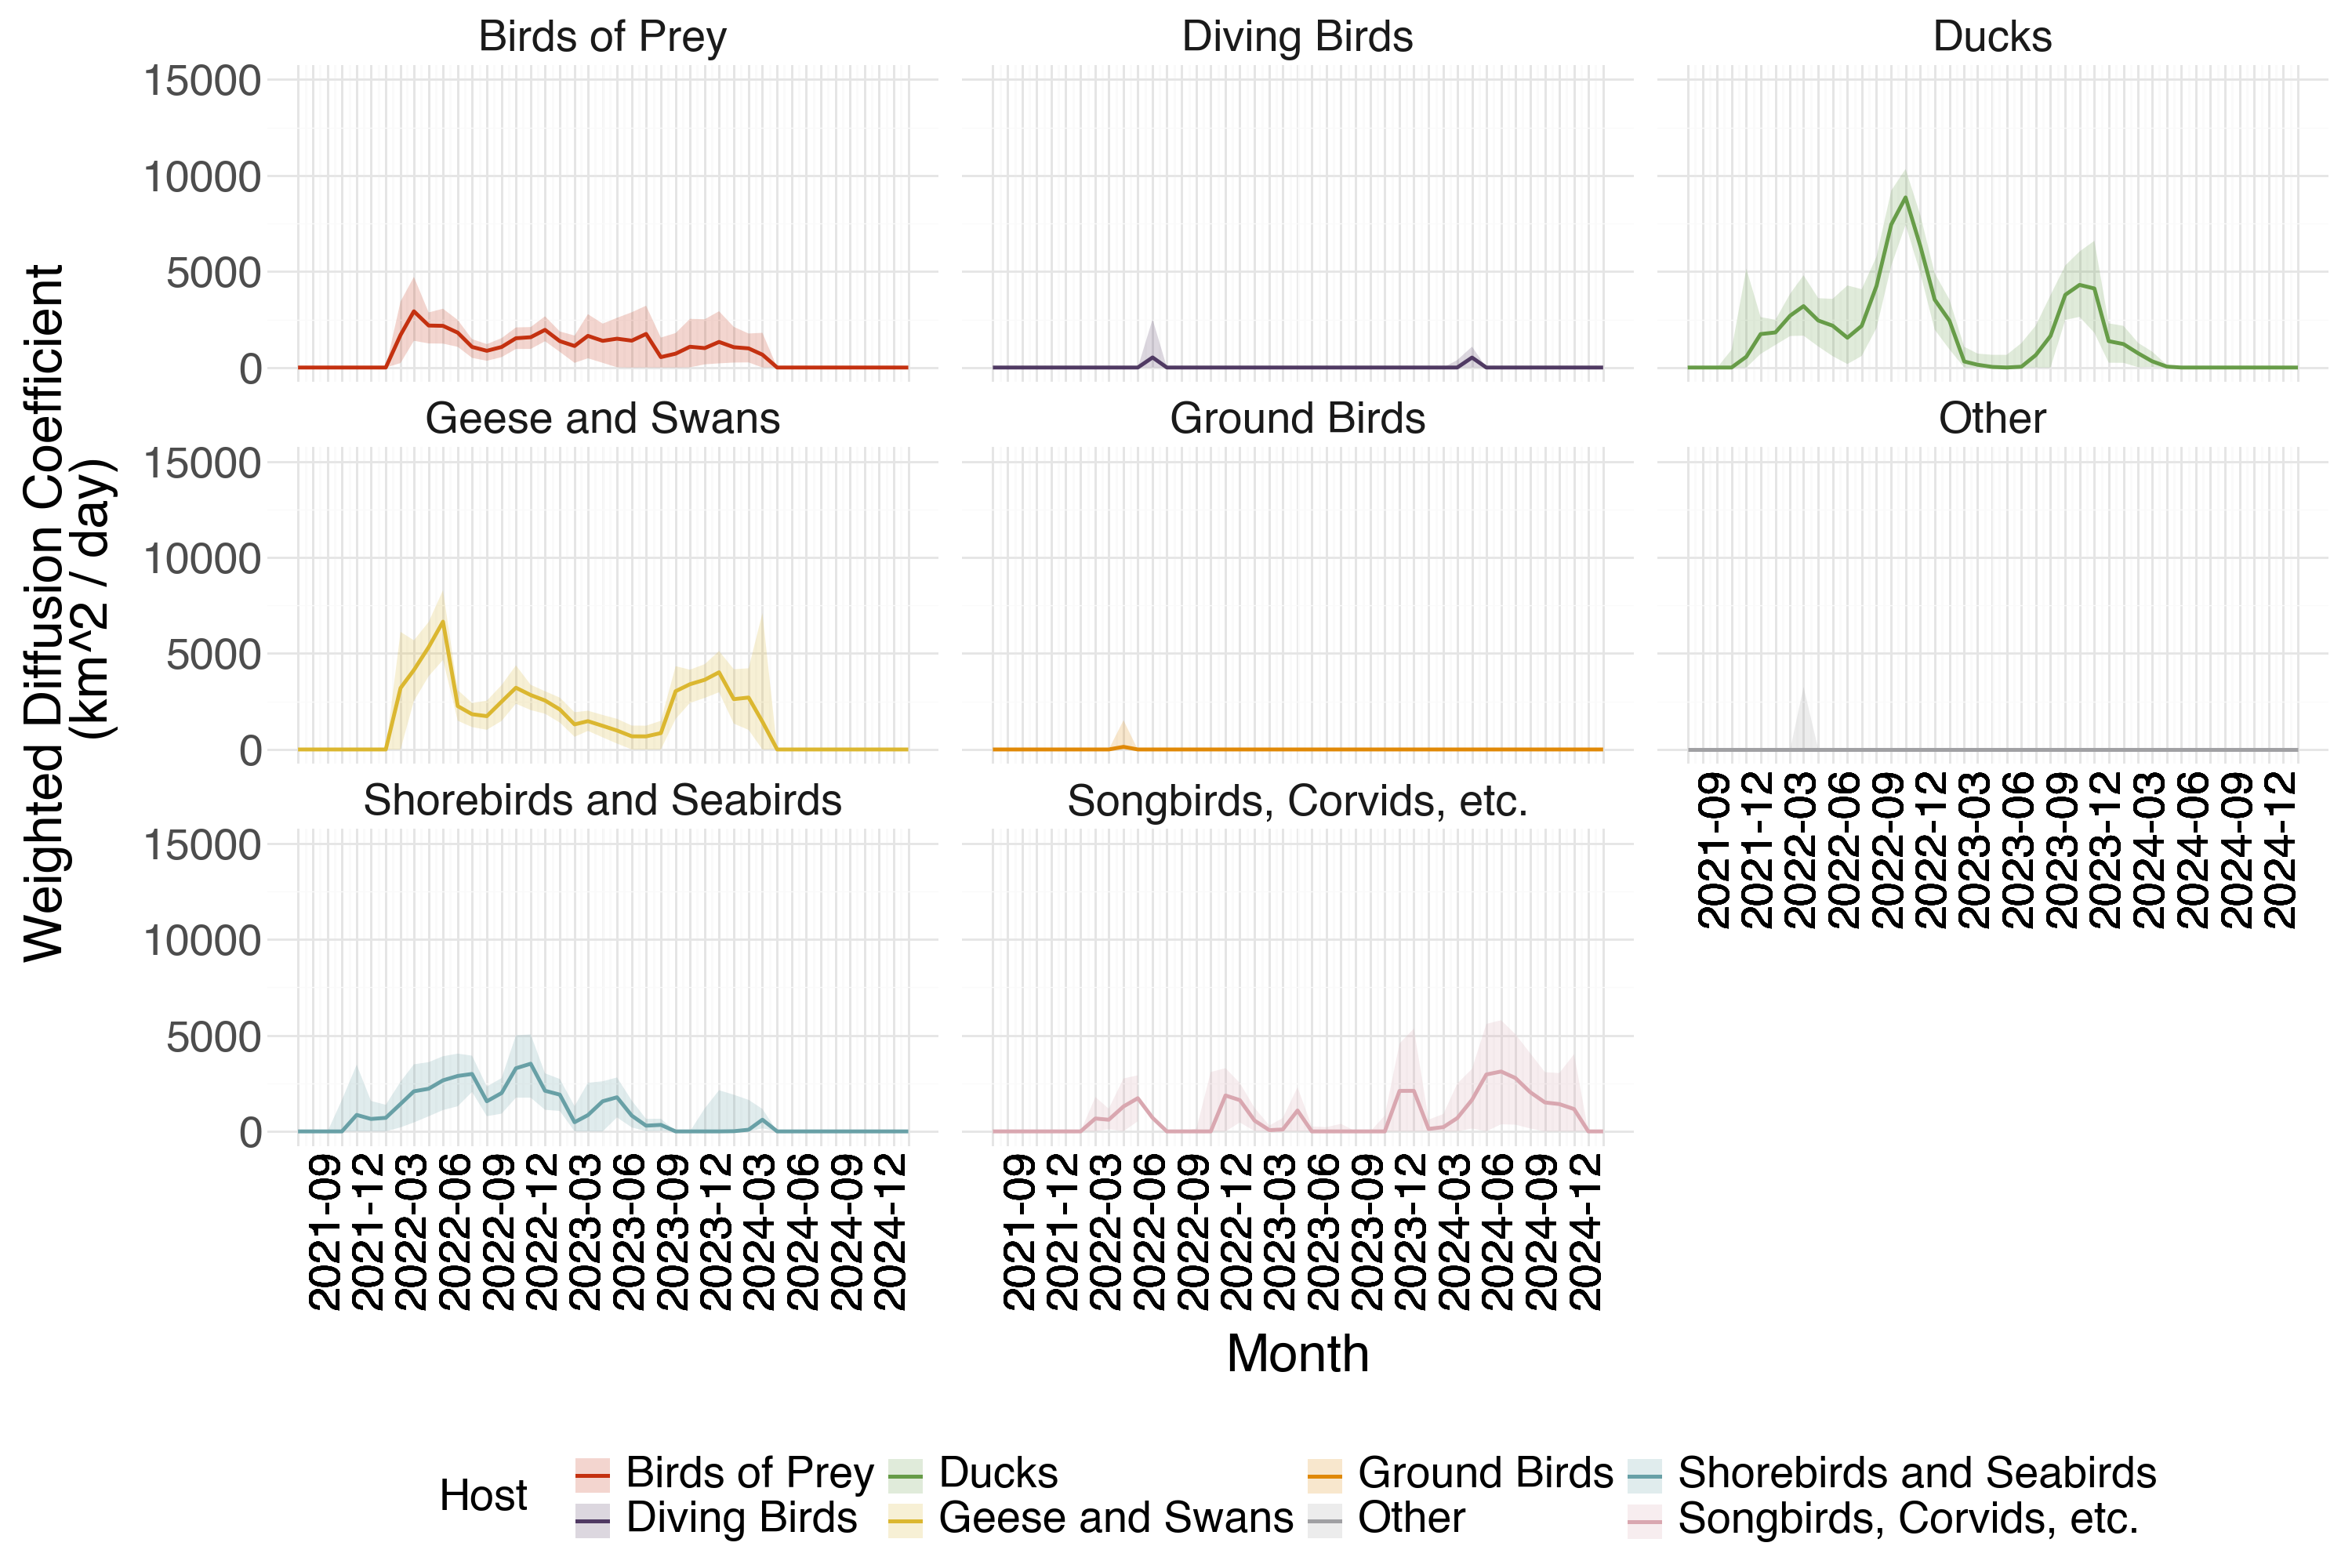

In [80]:
host_wdc_dates, host_wdc_date_labels = select_date_labels(hdi_host_wdc, "month")

monthly_wdc_plt = (
    ggplot(hdi_host_wdc, aes(x = "month", y = "median", color = "Host", group = "Host"))
    + geom_line(size = 1)
    + geom_ribbon(aes(x = "month", ymin = "lower", ymax = "upper", fill = "Host", group = "Host"), color = None, alpha = 0.2)
    + facet_wrap("Host", labeller = host_labels)
    + labs(x = "Month", y = "Weighted Diffusion Coefficient \n (km^2 / day)", color = "Host", fill = "Host")
    + scale_color_manual(host_colors, labels = host_labels)
    + scale_fill_manual(host_colors, labels = host_labels)
    + scale_x_date(breaks = host_wdc_dates, labels = host_wdc_date_labels)
    + ylim(-1, 15000)
    + theme_minimal()
    + theme(figure_size = (15,10), legend_text=element_text(size=20), axis_title_x = element_text(size = 24), text=element_text(size=20),
            axis_title_y = element_text(size = 24), axis_text_y = element_text(size = 20), axis_text_x = element_text(size = 20, rotation = 90, color = "black"))
    + theme(legend_position = "bottom", legend_direction = "horizontal")
)

monthly_wdc_plt.show()

In [28]:
# Print the plots you want cause YAYYYYY

# DIRECTORY = "./SERAPHIM/main-intro_equal-time-host-1000/plots/"
DIRECTORY = "./SERAPHIM/main-intro_equal-time-host-3000/plots/"
# DIRECTORY = "./SERAPHIM/main-intro_liveharvest/plots/"

# loc_scatter.save(f"{DIRECTORY}movement_scatter.png", format = "png", height=7, width=15, units = 'in', dpi = 750)
# speed_over_time.save(f"{DIRECTORY}speed_over_time.png", format = "png", height=7, width=15, units = 'in', dpi = 750)
# host_changes.save(f"{DIRECTORY}host_transitions_over_time.png", format = "png", height=10, width=15, units = 'in', dpi = 750)
# flyway_changes.save(f"{DIRECTORY}flyway_transitions_over_time.png", format = "png", height=10, width=15, units = 'in', dpi = 750)
# wdc_per_host_2.save(f"{DIRECTORY}wdc_over_posterior.png", format = "png", height=9, width=17, units = 'in', dpi = 750)
# monthly_wdc_plt.save(f"{DIRECTORY}monthly_wdc.png", format = "png", height=12, width=17, units = 'in', dpi = 750)
mcc_host_tofrom.save(f"{DIRECTORY}host_tofrom_MCC.png", format = "png", height=10, width=17, units = 'in', dpi = 750)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 17 x 10 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./SERAPHIM/main-intro_equal-time-host-3000/plots/host_tofrom_MCC.png


In [359]:
# monthly_wdc_plt.save(f"{DIRECTORY}monthly_wdc_v2.png", format = "png", height=12, width=17, units = 'in', dpi = 750)
# wdc_per_host_bar.save("./SERAPHIM/main-intro_equal-time-host-3000/plots/wdc_per_host_tester.png", format = "png", height=7, width=12, units = 'in', dpi = 750) # This is the test plot

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 7 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./SERAPHIM/main-intro_equal-time-host-3000/plots/wdc_per_host_tester.png


In [ ]:
# Below this is old code

In [ ]:
# Read in the MCC CSV

# FILE = "./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC.csv"
# FILE = "./SERAPHIM/nov2021-2024_no-suliformes/NAm_wild-aves_nov2021-2024_no-suliformes_ha_MCC.csv"
# FILE = "./SERAPHIM/nov2021-2024_no-suliformes_DTA/order_dta/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_order-DTA_MCC.csv"
# FILE = "./SERAPHIM/nov2021-2024_no-suliformes_DTA/duckduckgoose_dta/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_ddg-DTA_MCC.csv"
FILE = "./BEAST/continuous_phylogeography/results/2026-03-25_main-intro_equal-time-host-3000_ha_traits/main-intro_equal-time-host-3000_ha_traits_MCC.csv"

mcc = pd.read_csv(FILE, sep = ',')
print(mcc["startHost"].value_counts())

In [ ]:
mcc.head(7)

In [ ]:
# Compute the change in latitude between start and end nodes

mcc["changeLat"] = mcc["endLat"] - mcc["startLat"]

In [ ]:
# Compute the change in longitude between start and end nodes

mcc["changeLon"] = mcc["endLon"] - mcc["startLon"]

In [ ]:
# Add the whole starting and ending year

mcc["startYear_whole"] = mcc["startYear"].astype(str).str.split(".", expand=True)[0]
mcc["endYear_whole"] = mcc["endYear"].astype(str).str.split(".", expand=True)[0]

In [ ]:
# I got the solstice and equinox dates from this website
# https://greenwichmeantime.com/longest-day/equinox-solstice-2021-2030/

In [ ]:
# Compute the solstice and equinoxes in decimal format (developed by Chat GPT)

# List of date strings
date_strings = [
    "November 1 2021", "December 21 2021", "March 19 2022", "June 20 2022",
    "September 21 2022", "December 20 2022", "March 19 2023", "June 20 2023",
    "September 22 2023", "December 20 2023", "March 18 2024", "June 19 2024",
    "September 21 2024", "December 20 2024", "December 31 2024"
]

# Convert to datetime objects
dates = [datetime.strptime(date, "%B %d %Y") for date in date_strings]

# Function to convert date to decimal year
def to_decimal_year(date):
    year = date.year
    start_of_year = datetime(year, 1, 1)
    end_of_year = datetime(year + 1, 1, 1)
    year_length = (end_of_year - start_of_year).days
    day_of_year = (date - start_of_year).days
    return year + day_of_year / year_length

# Convert and print results
for date in dates:
    print(f"{date.strftime('%B %d %Y')}: {to_decimal_year(date):.5f}")

In [ ]:
def seasons(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn"
        elif 2022.96712 < y <= 2023.21096: # winter 2022-23
            return "winter"
        elif 2023.21096 < y <= 2023.46575: # spring 2023
            return "spring"
        elif 2023.46575 < y <= 2023.72329: # summer 2023
            return "summer"
        elif 2023.72329 < y <= 2023.96712: # autumn 2023
            return "autumn"
        elif 2023.96712 < y <= 2024.21038: # winter 2023-24
            return "winter"
        elif 2024.21038 < y <= 2024.46448: # spring 2024
            return "spring"
        elif 2024.46448 < y <= 2024.72131: # summer 2024
            return "summer"
        elif 2024.72131 < y <= 2024.96721: # autumn 2024
            return "autumn"
        elif y > 2024.96721: # winter 2024
            return "winter"
        else:
            return "unknown"

    df["season"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [ ]:
def season_year(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn_2021"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter_2021/22"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring_2022"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer_2022"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn_2022"
        elif 2022.96712 < y <= 2023.21096: # winter 2022-23
            return "winter_2022/23"
        elif 2023.21096 < y <= 2023.46575: # spring 2023
            return "spring_2023"
        elif 2023.46575 < y <= 2023.72329: # summer 2023
            return "summer_2023"
        elif 2023.72329 < y <= 2023.96712: # autumn 2023
            return "autumn_2023"
        elif 2023.96712 < y <= 2024.21038: # winter 2023-24
            return "winter_2023/24"
        elif 2024.21038 < y <= 2024.46448: # spring 2024
            return "spring_2024"
        elif 2024.46448 < y <= 2024.72131: # summer 2024
            return "summer_2024"
        elif 2024.72131 < y <= 2024.96721: # autumn 2024
            return "autumn_2024"
        elif y > 2024.96721: # winter 2024
            return "winter_2024"
        else:
            return "unknown"

    df["season_year"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [ ]:
def month(df, column):
    df["rounded"] = df[column].round(6)

    def get_month(y):
        if 2021.665753 <= y < 2021.747945: 
            return "september"
        elif 2021.747945 <= y < 2021.832877: 
            return "october"
        elif 2021.832877 <= y < 2021.915068: 
            return "november"
        elif 2021.915068 <= y < 2022.000000: 
            return "december"
        elif 2022.000000 <= y < 2022.084932: 
            return "january"
        elif 2022.084932 <= y < 2022.161644:
            return "february"
        elif 2022.161644 <= y < 2022.246575:
            return "march"
        elif 2022.246575 <= y < 2022.328767:
            return "april"
        elif 2022.328767 <= y < 2022.413699:
            return "may"
        elif 2022.413699 <= y < 2022.495890:
            return "june"
        elif 2022.495890 <= y < 2022.580822:
            return "july"
        elif 2022.580822 <= y < 2022.665753:
            return "august"
        elif 2022.665753 <= y < 2022.747945:
            return "september"
        elif 2022.747945 <= y < 2022.832877: 
            return "october"
        elif 2022.832877 <= y < 2022.915068:
            return "november"
        elif 2022.915068 <= y < 2023.000000:
            return "december"
        elif 2023.000000 <= y < 2023.084932:
            return "january"
        elif 2023.084932 <= y < 2023.161644:
            return "february"
        elif 2023.161644 <= y < 2023.246575:
            return "march"
        elif 2023.246575 <= y < 2023.328767:
            return "april"
        elif 2023.328767 <= y < 2023.413699:
            return "may"
        elif 2023.413699 <= y < 2023.495890:
            return "june"
        elif 2023.495890 <= y < 2023.580822:
            return "july"
        elif 2023.580822 <= y < 2023.665753:
            return "august"
        elif 2023.665753 <= y < 2023.747945:
            return "september"
        elif 2023.747945 <= y < 2023.832877:
            return "october"
        elif 2023.832877 <= y < 2023.915068:
            return "november"
        elif 2023.915068 <= y < 2024.000000:
            return "december"
        elif 2024.000000 <= y < 2024.084699:
            return "january"
        elif 2024.084699 <= y < 2024.163934:
            return "february"
        elif 2024.163934 <= y < 2024.248634:
            return "march"
        elif 2024.248634 <= y < 2024.330601:
            return "april"
        elif 2024.330601 <= y < 2024.415301:
            return "may"
        elif 2024.415301 <= y < 2024.497268:
            return "june"
        elif 2024.497268 <= y < 2024.581967:
            return "july"
        elif 2024.581967 <= y < 2024.666667:
            return "august"
        elif 2024.666667 <= y < 2024.748634:
            return "september"
        elif 2024.748634 <= y < 2024.833333:
            return "october"
        elif 2024.833333 <= y < 2024.915301:
            return "november"
        elif y >= 2024.915301:
            return "december"
        else:
            return "unknown"

    df["month"] = df["rounded"].apply(get_month)
    return df.drop("rounded", axis=1)

In [ ]:
# Add seasons as per the end_year
mcc_seasons = seasons(mcc, "endYear")

# Also add season_year
mcc_seasons = season_year(mcc_seasons, "endYear")

In [ ]:
# Add month as per the endYear

mcc_seas_mon = month(mcc_seasons, "endYear")

In [ ]:
# Add month_year column

mcc_seas_mon["month_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["month"].astype(str)

In [ ]:
# Anna's distance function

# branch_data = []
# node_counter = 1  # for assigning unique names to internal nodes
# node_names = {}   # map object -> unique name

# for obj in ll.Objects:
#     # Assign a unique name to internal nodes if they don't have one
#     if not hasattr(obj, 'name') or obj.name is None:
#         if obj not in node_names:
#             node_names[obj] = f"node_{node_counter}"
#             node_counter += 1
#         obj_name = node_names[obj]
#     else:
#         obj_name = obj.name

#     # Assign a name to the parent node as well
#     parent = obj.parent
#     if parent:
#         if not hasattr(parent, 'name') or parent.name is None:
#             if parent not in node_names:
#                 node_names[parent] = f"node_{node_counter}"
#                 node_counter += 1
#             parent_name = node_names[parent]
#         else:
#             parent_name = parent.name

#         if 'location1' in obj.traits and 'location2' in obj.traits and \
#            'location1' in parent.traits and 'location2' in parent.traits:

#             child_coords = (obj.traits['location1'], obj.traits['location2'])
#             parent_coords = (parent.traits['location1'], parent.traits['location2'])

#             branch_data.append({
#                 'child_name': obj_name,
#                 'parent_name': parent_name,
#                 'child_type': obj.branchType,
#                 'parent_type': parent.branchType,
#                 'child_lat': child_coords[0],
#                 'child_long': child_coords[1],
#                 'parent_lat': parent_coords[0],
#                 'parent_long': parent_coords[1],
#                 'child_time': obj.absoluteTime if hasattr(obj, 'absoluteTime') else None,
#                 'parent_time': parent.absoluteTime if hasattr(parent, 'absoluteTime') else None,
#                 'distance_km': geodesic(child_coords, parent_coords, ellipsoid='GRS-80').kilometers
#             })

# branches_df = pd.DataFrame(branch_data)
# branches_df.head()

In [ ]:
# Compute the distance between start and end nodes

def compute_distance(row):
    start = (row["startLat"], row["startLon"])
    end = (row["endLat"], row["endLon"])
    return geodesic(start, end, ellipsoid='GRS-80').kilometers

In [ ]:
mcc_seas_mon["dist_km"] = mcc_seas_mon.apply(compute_distance, axis=1)

In [ ]:
# Compute the time difference between start and end nodes

mcc_seas_mon["changeYear"] = mcc_seas_mon["endYear"] - mcc_seas_mon["startYear"]

In [ ]:
print(mcc_seas_mon["changeYear"].min())
negative_time = mcc_seas_mon[mcc_seas_mon["changeYear"] < 0].loc[0:,["node1", "node2", "changeYear", "startYear", "endYear"]]
print(len(negative_time))
print(negative_time)

In [ ]:
# Compute speed (distance over time)

mcc_seas_mon["branchSpeed"] = mcc_seas_mon["dist_km"] / mcc_seas_mon["changeYear"]
# mcc_seas_mon["wdc"] = (mcc_seas_mon["dist_km"] ** 2).sum() / (4 * (mcc_seas_mon["changeYear"] * 365)).sum()

In [ ]:
# Function: assign a direction of movement to each branch

def change_direction(df):
    df_new = df.copy()
    
    df_new.loc[df_new["changeLat"] < 0, "changeLat_direction"] = "south"
    df_new.loc[df_new["changeLat"] > 0, "changeLat_direction"] = "north"
    df_new.loc[df_new["changeLat"] == 0, "changeLat_direction"] = "none"
    df_new.loc[df_new["changeLon"] < 0, "changeLon_direction"] = "west"
    df_new.loc[df_new["changeLon"] > 0, "changeLon_direction"] = "east"
    df_new.loc[df_new["changeLon"] == 0, "changeLon_direction"] = "none"

    return(df_new)

In [ ]:
# Add columns for which branches are moving north, south, east, and west

mcc_seas_mon_withDirections = change_direction(mcc_seas_mon)

In [ ]:
# Match lat/long to a flyway

In [ ]:
# Anna's FIPS code assignment function

# def get_block_group_fips(lat, lon):
#     url = f"https://geo.fcc.gov/api/census/block/find?latitude={lat}&longitude={lon}&censusYear=2010&format=json"
#     response = requests.get(url)
#     data = response.json()
#     block_fips = data['Block']['FIPS']
#     block_group_fips = block_fips[:12]  # Truncate to 12 digits
#     return block_group_fips

# # Example
# print(get_block_group_fips(40.7128, -74.0060))  # Should return 12-digit FIPS

In [ ]:
# First try by Clara

# from geopy.geocoders import Nominatim

# geolocator = Nominatim(user_agent="cm_plotting_app")

# def state(df, column1, column2):
#     coords = str((df[column1], df[column2]))
#     location = geolocator.reverse(coords)
#     state = location.raw["address"].get("state")
#     return state

In [ ]:
# Second try by Chat GPT - too slow!

# Set up geolocator globally
# geolocator = Nominatim(user_agent="geo_lookup_app")

# def reverse_geocode(lat, lon):
#     try:
#         location = geolocator.reverse((lat, lon), language='en')
#         if location and 'state' in location.raw['address']:
#             return location.raw['address']['state']
#         else:
#             return None
#     except GeocoderTimedOut:
#         time.sleep(1)
#         return reverse_geocode(lat, lon)  # Retry once
#     except Exception as e:
#         print(f"Error for ({lat}, {lon}): {e}")
#         return None

# def add_state_column(df, lat_col, lon_col):
#     df["state"] = df.apply(lambda row: reverse_geocode(row[lat_col], row[lon_col]), axis=1)
#     return df

In [ ]:
# Need a shapefile to dictate polygon boundaries

# North America shapefile
NAm_shp_path = "./metadata/shapefiles/north_america/north_america.shp"
NAm_gdf = gpd.read_file(NAm_shp_path)

# Downloaded US shapefile from Natural Earth
# Downloaded Canadian province shapefile from: https://open.canada.ca/data/en/dataset/a883eb14-0c0e-45c4-b8c4-b54c4a819edb/resource/12c03de6-c3f7-4f5f-bb5c-d479f2332842
# Downloaded Mexican state shapefile from: https://github.com/jschleuss/mexican-states

In [ ]:
# I would like to see what is happening in my shapefile DF

NAm_gdf["geometry_name"] = NAm_gdf["name"].combine_first(NAm_gdf["PRNAME"])
columns = ["geometry", "geometry_name", "place", "type", "latitude", "longitude", "fips", "region", "gadm_level"]
NAm_gdf = NAm_gdf.loc[0:, columns]

NAm_gdf = NAm_gdf.to_crs("EPSG:4326")

In [ ]:
NAm_gdf_validated = NAm_gdf.copy()
NAm_gdf_validated["geometry"] = NAm_gdf_validated["geometry"].apply(make_valid)

# This takes a little while

In [ ]:
print(NAm_gdf_validated[~NAm_gdf_validated.is_valid])

In [ ]:
# Create geometries for each start and end point in the MCC tree

mcc_seas_mon_withDirections['startGeometry'] = mcc_seas_mon_withDirections.apply(lambda row: Point(row['startLon'], row['startLat']), axis=1)
mcc_seas_mon_withDirections['endGeometry'] = mcc_seas_mon_withDirections.apply(lambda row: Point(row['endLon'], row['endLat']), axis=1)

geop_mcc_seas_mon_withDirections_start = gpd.GeoDataFrame(mcc_seas_mon_withDirections, geometry='startGeometry', crs="EPSG:4326")
geop_mcc_seas_mon_withDirections_end = gpd.GeoDataFrame(mcc_seas_mon_withDirections, geometry='endGeometry', crs="EPSG:4326")

geop_mcc_seas_mon_withDirections_start = geop_mcc_seas_mon_withDirections_start.set_crs("EPSG:4326", allow_override=True)
geop_mcc_seas_mon_withDirections_end = geop_mcc_seas_mon_withDirections_end.set_crs("EPSG:4326", allow_override=True)

# print(geop_mcc_seas_mon_withDirections_start)

In [ ]:
# Function: use gpd.sjoin to assign coordinates to the state (made by Chat GPT)

def assign_state(df, geom_col, states_gdf, new_col):
    temp = df.set_geometry(geom_col, inplace=False)

    # CRS check and force match
    if temp.crs != states_gdf.crs:
        temp = temp.to_crs(states_gdf.crs)

    result = gpd.sjoin(temp, states_gdf[["geometry_name", "geometry"]], how="left", predicate="within")
    
    result_renamed = result.rename(columns={"geometry_name": new_col})
    
    # Detect duplicated indices (geometries within multiple states)
    duplicate_indices = result_renamed.index[result_renamed.index.duplicated(keep=False)]

    # Assign 'unknown' to all duplicated rows
    result_renamed.loc[duplicate_indices, new_col] = "unknown"

    # Drop all but the first instance of each original index
    deduped = result_renamed[~result_renamed.index.duplicated(keep='first')]

    # Build final series and align with original df
    state_series = deduped[new_col]
    
    # return print(result_renamed[result_renamed.index.isin(duplicate_indices)])
    return state_series.reindex(df.index)

In [ ]:
mcc_seas_mon_withDirections["startState"] = assign_state(geop_mcc_seas_mon_withDirections_start, "startGeometry", NAm_gdf, "startState")
# Indexes 3144 and 3294 have two start states?
mcc_seas_mon_withDirections["endState"] = assign_state(geop_mcc_seas_mon_withDirections_end, "endGeometry", NAm_gdf, "endState")
# Index 2086 has two end states?

In [ ]:
# Fix state/province names

# No French! (also some Mexico changes)
no_french_dict = {"Newfoundland and Labrador / Terre-Neuve-et-Labrador":"Newfoundland",
                 "Prince Edward Island / Île-du-Prince-Édouard":"Prince Edward Island",
                 "British Columbia / Colombie-Britannique":"British Columbia",
                 "Northwest Territories / Territoires du Nord-Ouest":"Northwest Territories",
                 "Quebec / Québec":"Quebec",
                 "Nova Scotia / Nouvelle-Écosse":"Nova Scotia",
                 "New Brunswick / Nouveau-Brunswick":"New Brunswick",
                 "Coahuila de Zaragoza":"Coahuila",
                 "Veracruz de Ignacio de la Llave":"Veracruz",
                 "Michoacán de Ocampo":"Michoacán"
                 }

# Make the above adjustments (if 
mcc_seas_mon_withDirections["startState"] = mcc_seas_mon_withDirections["startState"].map(no_french_dict).fillna(mcc_seas_mon_withDirections["startState"]) 
mcc_seas_mon_withDirections["endState"] = mcc_seas_mon_withDirections["endState"].map(no_french_dict).fillna(mcc_seas_mon_withDirections["endState"])

In [ ]:
# Function: Standardize state names

def fix_state_name(name):
    if pd.isna(name):
        return name
    replacements = {"é": "e", "á": "a", "í": "i", "ó": "o"}
    name = name.lower()
    name = name.replace("-", "").replace(" ", "").replace("'", "")
    for accented, plain in replacements.items():
        name = name.replace(accented, plain)
    return name

In [ ]:
# Standardize the states in both startState and endState

mcc_seas_mon_state = mcc_seas_mon_withDirections.copy()

mcc_seas_mon_state["startState"] = mcc_seas_mon_state["startState"].apply(fix_state_name)
mcc_seas_mon_state["endState"] = mcc_seas_mon_state["endState"].apply(fix_state_name)

In [ ]:
# Upload the state and flyway and turn it into a dictionary

# Upload the CSV of the state and flyway
state_flyway_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

state_flyway_df = pd.read_csv(state_flyway_csv, sep = ',') 

# Turn this CSV into a dictionary
state_flyway_dict = state_flyway_df.set_index("location").to_dict(orient="index")

In [ ]:
# Add flyway

mcc_seas_mon_state_flyway = mcc_seas_mon_state.copy()

mcc_seas_mon_state_flyway["startFlyway"] = mcc_seas_mon_state_flyway["startState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))
mcc_seas_mon_state_flyway["endFlyway"] = mcc_seas_mon_state_flyway["endState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))

In [ ]:
# I wanted to check if either column has "unknown" values

# print(mcc_seas_mon_state_flyway["startFlyway"].value_counts())
# print(mcc_seas_mon_state_flyway["endFlyway"].value_counts())

print(mcc_seas_mon_withDirections["startFlyway"].value_counts())
print(mcc_seas_mon_withDirections["endFlyway"].value_counts())

# Both do have unknowns, probably because those coordinates are in the ocean

In [ ]:
# Create a DataFrame of lat/lon from the geometries
def geom_to_df(geom, region_name):
#     if isinstance(geom, Polygon):
#         coords = list(geom.exterior.coords)
#         df = pd.DataFrame(coords, columns=['lon', 'lat'])
#         df['region'] = region_name
#         df['group'] = f"{region_name}_0"
#         return df

#     elif isinstance(geom, MultiPolygon):
#         dfs = []
#         for i, part in enumerate(geom.geoms):
#             coords = list(part.exterior.coords)
#             df = pd.DataFrame(coords, columns=['lon', 'lat'])
#             df['region'] = region_name
#             df['group'] = f"{region_name}_{i}"
#             dfs.append(df)
#             # Add NaN to separate parts (important for line-based plotting)
            # dfs.append(pd.DataFrame({
            #     'lon': [np.nan],
            #     'lat': [np.nan],
            #     'region': [region_name],
            #     'group': [f"{region_name}_{i}"]
            # }))
#         return pd.concat(dfs, ignore_index=True)

    if isinstance(geom, LineString):
        coords = list(geom.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiLineString):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
#            dfs.append(pd.DataFrame({'lon': [np.nan],'lat': [np.nan],'region': [region_name],'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

In [ ]:
# I suspect all the unknowns are either in the Atlantic or Pacific Ocean, but I will need to be sure

# subset dataframe to just those with unknown start flyway
unknown_starts = mcc_seas_mon_state_flyway[mcc_seas_mon_state_flyway["startFlyway"] == "unknown"]
unknown_ends = mcc_seas_mon_state_flyway[mcc_seas_mon_state_flyway["endFlyway"] == "unknown"]

# Maybe plot these? Or set a boundary and see if they're beyond it
COASTLINES = "./metadata/shapefiles/ne_10m_coastline/ne_10m_coastline.shp"
coastlines_gdf = gpd.read_file(COASTLINES)
coastlines_gdf = coastlines_gdf.to_crs("EPSG:4326")

# Optional cleaning
coastlines_gdf = coastlines_gdf[coastlines_gdf.is_valid]
coastlines_gdf = coastlines_gdf[~coastlines_gdf.geometry.is_empty]

map_df = pd.concat([geom_to_df(row.geometry, row['featurecla']) for idx, row in coastlines_gdf.iterrows()], ignore_index=True)
filtered_map_df = map_df[
    (map_df['lat'] >= 0) & (map_df['lat'] <= 80) &
    (map_df['lon'] >= -180) & (map_df['lon'] <= -30)
]

starts = (
    ggplot(filtered_map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_starts, mapping=aes(x='startLon', y='startLat'), color='blue', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Starts')
)
#starts.show()

ends = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_ends, mapping=aes(x='endLon', y='endLat'), color='red', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Ends')
)
#ends.show()

In [ ]:
# After checking with Louise, the plan is to cluster unknown starts and ends and set them into a flyway

def set_unknown_points(df, column1, column2, column3):

    df_new = df.copy()

    unknown = df_new[column1] == "unknown"
    lat = df_new[column2]
    long = df_new[column3]

    # Conditions for assigning flyways
    cond1 = (unknown) & (lat < 20) # If latitude < 20, then Central Flyway
    cond2 = (unknown) & (lat > 20) & (long > -85) # If latitude > 20 and longitude > -85, then Atlantic Flyway
    cond3 = (unknown) & (lat > 20) & (long.between(-94, -85)) # If latitude > 20 and -94 ≤ longitude < -85, then Mississippi Flyway
    cond4 = (unknown) & (lat > 20) & (long.between(-110, -94)) # If latitude > 20 and -110 ≤ longitude < -94, then Central Flyway
    cond5 = (unknown) & (lat > 20) & (long < -110) # If latitude > 20 and longitude < -110, then Pacific Flyway

    # Assign new values based on conditions
    df_new.loc[cond1, column1] = "CentralFlyway"
    df_new.loc[cond2, column1] = "AtlanticFlyway"
    df_new.loc[cond3, column1] = "MississippiFlyway"
    df_new.loc[cond4, column1] = "CentralFlyway"
    df_new.loc[cond5, column1] = "PacificFlyway"

    return(df_new)

In [ ]:
# Update the unknown start and end flyways

mcc_seas_mon_state_flyway_upt1 = set_unknown_points(mcc_seas_mon_state_flyway, "startFlyway", "startLat", "startLon")
mcc_seas_mon_state_flyway_upt2 = set_unknown_points(mcc_seas_mon_state_flyway_upt1, "endFlyway", "endLat", "endLon")

In [ ]:
# Add a column if the start flyway and end flyway are different

# Initialize the column with default value
mcc_seas_mon_state_flyway_upt2["changeFlyway"] = "yes"

# Assign 'yes' where start == end
mcc_seas_mon_state_flyway_upt2.loc[mcc_seas_mon_state_flyway_upt2["startFlyway"] == mcc_seas_mon_state_flyway_upt2["endFlyway"], "changeFlyway"] = "no"

In [ ]:
# Add a column if start host order and end host order are different

# Initialize the column with default value
mcc_seas_mon_state_flyway_upt2["changeOrder"] = "yes"

# Assign 'yes' where start == end
mcc_seas_mon_state_flyway_upt2.loc[mcc_seas_mon_state_flyway_upt2["startOrder"] == mcc_seas_mon_state_flyway_upt2["endOrder"], "changeOrder"] = "no"

In [ ]:
# Print this updated MCC CSV

#mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC_updated.csv", sep = ',')
# mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes/NAm_wild-aves_nov2021-2024_no-suliformes_ha_MCC_updated.csv", sep = ',')
# mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA/NAm_wild-aves_nov2021-2024_no-suliformes_contphyl-order_MCC_updated.csv", sep = ',')
# mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes_DTA/order_dta/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_order-DTA_MCC_updated.csv", sep = ',')
mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes_DTA/duckduckgoose_dta/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_ddg-DTA_MCC_updated.csv", sep = ',')

In [ ]:
# Optional: subset the mcc CSV to branches traveling a certain distance

mcc_over100km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 100]
mcc_over200km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 200]
mcc_over300km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 300]
mcc_over500km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 500]

In [ ]:
# GOTTA CHANGE ALL THE DATAFRAMES FROM HERE DOWN!!!!!!

In [ ]:
# Set the dataframe for all plotting and statistics

# MCCDATA = mcc_seas_mon_state_flyway_upt2
# MCCDATA = mcc_over100km
#MCCDATA = mcc_over200km
# MCCDATA = mcc_over300km
#MCCDATA = mcc_over500km
MCCDATA = mcc_seas_mon

print(len(MCCDATA))

In [ ]:
# Plot 1: change in direction of all points

year_colors = {"2021":"#AA7722",
               "2022":"#5E9B82",
               "2023":"#C593D1",
               "2024":"#2B57B3"
              }

years = ["2021",
        "2022",
        "2023"
        ]

MCCDATA_filtered = MCCDATA[MCCDATA["endYear_whole"].isin(years)]

all_time_scatter = (
    ggplot(MCCDATA, 
           aes(x = "changeLon", y = "changeLat", color = "endYear_whole")) 
    + geom_point(alpha = 0.5)
#    + stat_ellipse(type='t', level=0.95, linetype='dashed', size=1)
    + scale_color_manual(values=year_colors)
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

all_time_scatter.show()

In [ ]:
grouped = MCCDATA.groupby(["season", "endYear_whole"])

dictionary = {}

for group in grouped:
    dictionary[group[0]] = {}
    total = len(group[1])
    nw = len(group[1].loc[(group[1]["changeLat_direction"] == "north") & (group[1]["changeLon_direction"] == "west")])
    ne = len(group[1].loc[(group[1]["changeLat_direction"] == "north") & (group[1]["changeLon_direction"] == "east")])
    sw = len(group[1].loc[(group[1]["changeLat_direction"] == "south") & (group[1]["changeLon_direction"] == "west")])
    se = len(group[1].loc[(group[1]["changeLat_direction"] == "south") & (group[1]["changeLon_direction"] == "east")])
    prop_nw = (nw/total) * 100
    prop_ne = (ne/total) * 100
    prop_sw = (sw/total) * 100
    prop_se = (se/total) * 100

    dictionary[group[0]] = {"percent-NW": prop_nw, "percent-NE": prop_ne, "percent-SW": prop_sw, "percent-SE": prop_se}

df = pd.DataFrame(dictionary).T

In [ ]:
df = df.reset_index()

In [ ]:
print(df)

In [ ]:
# Plot 1.5: change in direction, colored by season, facetted by year

season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }

host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

season_order = ["autumn", "winter", "spring", "summer"]
MCCDATA["season"] = pd.Categorical(MCCDATA["season"], categories=season_order, ordered=True)

seasonal_scatter = (
    # ggplot(MCCDATA, aes(x = "changeLon", y = "changeLat", color = "season"))
    ggplot(MCCDATA, aes(x = "changeLon", y = "changeLat", color = "endHost"))
    + geom_point(alpha = 0.5)
    # + stat_ellipse(type='t', level=0.95, size=1)
    + scale_color_manual(values=host_colors)
    # + facet_wrap("endYear_whole")
    + facet_grid("endYear_whole ~ season")
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
    + theme(figure_size = (10, 10))
)

seasonal_scatter.show()
# seasonal_scatter.save(filename = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/seasonal_scatter.pdf', height=7, width=10, units = 'in', dpi=750)
#seasonal_scatter.save(filename = './SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA//output_plots/seasonal_scatter.pdf', height=7, width=10, units = 'in', dpi=750)

In [ ]:
# Plot 3: Proportion of branchs moving north/south, east/west during each year and each season

season_year_order = ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022", "winter_2022/23", 
                     "spring_2023", "summer_2023", "autumn_2023", "winter_2023/24", "spring_2024", "summer_2024", 
                     "autumn_2024", "winter_2024"]
MCCDATA["season_year"] = pd.Categorical(MCCDATA["season_year"], categories=season_year_order, ordered=True)

prop_direction_latitude = (
    ggplot(MCCDATA, aes(x = "season_year", fill = "changeLat_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"north": "#2B57B3", "south": "#AA7722"}, name="Direction", 
                            labels={"north":"North", "south": "South"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_longitude = (
    ggplot(MCCDATA, aes(x = "season_year", fill = "changeLon_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"east": "#5E9B82", "west": "#C593D1"}, name="Direction", 
                            labels={"east":"East", "west": "West"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_latitude.show()
prop_direction_longitude.show()

In [ ]:
# Plot 3.5: Proportion of branchs moving north/south, east/west during each month

MCCDATA["month_year"] = MCCDATA["month_year"].astype(str)

month_order = ["2021_september", "2021_october","2021_november","2021_december", "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
               "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december","2023_january", "2023_february", "2023_march", "2023_april", 
               "2023_may", "2023_june", "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", "2024_january", "2024_february", 
               "2024_march", "2024_april", "2024_may", "2024_june","2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]

MCCDATA["month_year"] = pd.Categorical(MCCDATA["month_year"], categories=month_order, ordered=True)

prop_direction_latitude_month = (
    ggplot(MCCDATA, aes(x = "month_year", fill = "changeLat_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"north": "#2B57B3", "south": "#AA7722"}, name="Direction", 
                            labels={"north":"North", "south": "South"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_longitude_month = (
    ggplot(MCCDATA, aes(x = "month_year", fill = "changeLon_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"east": "#5E9B82", "west": "#C593D1"}, name="Direction", 
                            labels={"east":"East", "west": "West"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_latitude_month.show()
prop_direction_longitude_month.show()

In [ ]:
# # Maybe this will come in handy... at some point
# # Makes a dataframe with the proportion in each column

# # Make a new dataframe and calculate the proportion of each direction
# directions_df = pd.DataFrame({"season_year": ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022",
#                              "winter_2022/23", "spring_2023", "summer_2023", "autumn_2023",
#                              "winter_2023/24", "spring_2024", "summer_2024", "autumn_2024", "winter_2024"]})

# for season, group_df in mcc_seas_mon_withDirections.groupby("season_year"):
   
#     total = len(group_df)
    
#     prop_north = len(group_df[group_df["changeLat_direction"] == "north"]) / total
#     prop_south = len(group_df[group_df["changeLat_direction"] == "south"]) / total
#     prop_east  = len(group_df[group_df["changeLon_direction"] == "east"]) / total
#     prop_west  = len(group_df[group_df["changeLon_direction"] == "west"]) / total

#     directions_df.loc[directions_df["season_year"] == season, "north"] = prop_north
#     directions_df.loc[directions_df["season_year"] == season, "south"] = prop_south
#     directions_df.loc[directions_df["season_year"] == season, "east"]  = prop_east
#     directions_df.loc[directions_df["season_year"] == season, "west"]  = prop_west 

In [ ]:
# Plots 3, 4, 5: speed and distance over time 

speed_over_time = (
    ggplot(MCCDATA) 
    + geom_point(aes(x = "endYear", y = "branchSpeed", color = "season"), alpha=0.25)
#    + facet_wrap("endYear_whole")
    + scale_color_manual(values=season_colors)
    + scale_y_log10()
    + geom_smooth(aes(x = "endYear", y = "branchSpeed"), method='loess', span=0.4)
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr) (Log)")
)

speed_per_season = (
    ggplot(MCCDATA, aes(x = "season_year", y = "branchSpeed", color = "season", fill = "season"))
    + geom_violin()
    + ylim(-5, 10000)
    + scale_fill_manual(values=season_colors)
    + scale_color_manual(values=season_colors)
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + labs(x = "Season", y = "Speed per Branch (km/yr)")
)

dist_over_time = (
    ggplot(MCCDATA, aes(x = "endYear", y = "dist_km", color = "season")) 
    + geom_point(alpha=0.5)
    + scale_color_manual(values=season_colors)
    # + scale_y_log10()
#    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Distance per Branch (km)")
)

dist_vs_speed = (
    ggplot(MCCDATA, aes(x = "dist_km", y = "branchSpeed"))
    + geom_line()
    + scale_y_log10()
    + labs(x = "Distance (km)", y = "Speed per Branch (km/yr)")
)

speed_over_time.show()
# speed_over_time.save(filename = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/speed_over_time.pdf', height=7, width=10, units = 'in', dpi=750)
# speed_per_season.show()
# dist_over_time.show()
#dist_over_time.save(filename = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/distance_over_time.pdf', height=7, width=10, units = 'in', dpi=750)
# dist_vs_speed.show()

In [ ]:
print(MCCDATA["branchSpeed"].loc[MCCDATA["endYear"] < 2022.413699].mean())
print(MCCDATA["branchSpeed"].loc[(2023.0 <= MCCDATA["endYear"]) & (MCCDATA["endYear"] < 2024)].mean())

In [ ]:
# Plot 6: Histogram of distance (km) per branch

dist_freq = (
    ggplot(MCCDATA, aes(x = "dist_km")) 
    + geom_histogram(binwidth = 50) # Each bin is 50 km
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Frequency")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_freq.show()

# I'm just curious what it looks like below 100 km

just_curious = MCCDATA[MCCDATA["dist_km"] < 100]
print(len(just_curious))
just_curious = (
    ggplot(just_curious, aes(x = "dist_km"))
    + geom_histogram(bins = 10)
)
just_curious.show()

In [ ]:
# Plot 8: average lat and lon per month

avg_latitude = (
    ggplot(MCCDATA)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLat", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLat", color = "season"))
    + labs(x = "Month", y = "Ending Latitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)


avg_longitude = (
    ggplot(MCCDATA)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLon", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLon", color = "season"))
    + labs(x = "Month", y = "Ending Longitude")
    + scale_color_manual(values = season_colors)
    + ylim(-200, 0)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)

avg_latitude.show()
avg_longitude.show()

In [ ]:
# Plot 9: the proportion of branches that cross flyways

prop_df = pd.DataFrame(["no", "yes"]).rename({0:"changeFlyway"}, axis = 1)

# prop_df.loc[prop_df["changeFlyway"] == "no", "value"] = len(mcc_seas_mon_flyways_upt2.loc[mcc_seas_mon_flyways_upt2["changeFlyway"] == "no"])
# prop_df.loc[prop_df["changeFlyway"] == "yes", "value"] = len(mcc_seas_mon_flyways_upt2.loc[mcc_seas_mon_flyways_upt2["changeFlyway"] == "yes"])

prop_df.loc[prop_df["changeFlyway"] == "no", "proportion"] = (len(MCCDATA.loc[MCCDATA["changeFlyway"] == "no"])) / 12024
prop_df.loc[prop_df["changeFlyway"] == "yes", "proportion"] = (len(MCCDATA.loc[MCCDATA["changeFlyway"] == "yes"])) / 12024

print(prop_df)

proportion_changeFlyway = (
    ggplot(prop_df, aes(x = "changeFlyway", y = "proportion"))
    + geom_col()
    + labs(x = "Branch Crossed Flyways", y = "Percent")
    + theme(figure_size = (15, 5))
)

proportion_changeFlyway.show()

In [ ]:
# Plot 10: On a histogram of distance traveled, what proportion cross flyways

dist_changeFlyway = (
    ggplot(MCCDATA, aes(x = "dist_km", fill = "changeFlyway"))
    + geom_histogram(binwidth = 50)
    + scale_fill_manual(values={"no": "#5E9B82", "yes": "#C593D1"}, name="Change Flyway?")
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    # + scale_y_log10()
    + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Proportion of Branches Cross Flyways")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_changeFlyway_logged = (
    ggplot(MCCDATA, aes(x = "dist_km", fill = "changeFlyway"))
    + geom_histogram(binwidth = 50)
    + scale_fill_manual(values={"no": "#5E9B82", "yes": "#C593D1"}, name="Change Flyway?")
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    + scale_y_log10()
    # + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Proportion of Branches Cross Flyways (Log)")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_changeFlyway.show()
dist_changeFlyway_logged.show()

In [ ]:
# Plot 11, 12, 13, 14, 15, 16, 17: applicable if you have host designations integrated into the csv

# host_colors = {"accipitriformes/strigiformes":"#7E3636",
#                "anseriformes":"#566F5E",
#                "charadriiformes/shorebirds":"#FEC260",
#                "other":"#65518A"
#               }

# host_colors = {"accipitriformes/strigiformes":"#A66F6F",
#                    "duck":"#879E82",
#                    "geese_swans": "#D69E49", 
#                    "charadriiformes/shorebirds":"#68A0A6",
#                    "other":"#D9A7B0"
#                   }

# start_hosts = (
#     ggplot(MCCDATA, aes(x = "endOrder", fill = "endOrder"))
#     + geom_col(stat = "count")
#     + scale_fill_manual(values=host_colors)
#     + theme(axis_text_x=element_text(rotation=30, hjust=1))
#     + labs(x = "Ending Node - Host Order", y = "Frequency")
# )

# change_hosts = (
#     ggplot(MCCDATA, aes(x = "changeOrder"))
#     + geom_col(stat = "count")
#     + labs(x = "Change in Host Order", y = "Frequency")
# ) 

# Distance over time colored by host
# dist_over_time_host = (
#     ggplot(MCCDATA, aes(x = "endYear", y = "dist_km", color = "startOrder")) 
#     + geom_point(alpha=0.5)
#     + scale_color_manual(values=host_colors)
#     # + scale_y_log10()
#     + facet_wrap("startOrder")
#     + labs(x = "Time at End Node", y = "Distance per Branch (km)")
# )

# Speed over time colored by host
speed_over_time_host = (
    ggplot(MCCDATA, aes(x = "endYear", y = "branchSpeed", color = "startHost")) 
    + geom_point(alpha=0.5)
    + geom_smooth(aes(x = "endYear", y = "branchSpeed"), color = "black")
    + facet_wrap("startHost")
    + scale_color_manual(values=host_colors)
    # + scale_y_log10()
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr)")
)

# Compute the mean/medians by startOrder if you want to display them in speed_per_host1
medians = MCCDATA.groupby("startHost", as_index=False)["branchSpeed"].median()
medians = medians.rename(columns={"branchSpeed": "medianSpeed"})
means = MCCDATA.groupby("startHost", as_index=False)["branchSpeed"].mean()
means = means.rename(columns={"branchSpeed": "meanSpeed"})
means["label"] = "Mean = " + means["meanSpeed"].round(2).astype(str)
hpd5 = MCCDATA.groupby("startHost", as_index=False)["branchSpeed"].quantile(0.05).rename(columns={"branchSpeed":"5_hpd"})
hpd95 = MCCDATA.groupby("startHost", as_index=False)["branchSpeed"].quantile(0.95).rename(columns={"branchSpeed":"95_hpd"})
medians = medians.merge(hpd95, on = "startHost")
medians = medians.merge(hpd5, on = "startHost")
medians["label"] = "90% HPD = " + hpd5["5_hpd"].round(2).astype(str) + " - " + hpd95["95_hpd"].round(2).astype(str)

speed_per_host1 = (
    ggplot(MCCDATA, aes(x = "startHost", y = "branchSpeed", color = "startHost", fill = "startHost")) 
    + geom_violin(adjust=20)
    # + geom_jitter()
    # + geom_crossbar(aes(x="startHost", y="medianSpeed", ymin="medianSpeed", ymax="medianSpeed"), data=medians, width=0.3, color="red")
    # + geom_crossbar(aes(x="startHost", y="meanSpeed", ymin="meanSpeed", ymax="meanSpeed"), data=means, width=0.3, color="black")
    + scale_fill_manual(values=host_colors)
    + scale_color_manual(values=host_colors)
    # + ylim(0,1e8)
    + scale_y_log10()
    + labs(x = "Host", y = "Speed per Branch (km/yr) (Log)")
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

speed_per_host2 = (
    ggplot(MCCDATA, aes(x = "branchSpeed", fill = "startHost", color = "startHost"))
    # + geom_area(stat = "count", alpha = 0.3)
    # + geom_density(alpha=0.65)
    + geom_histogram()
    + geom_text(means, aes(x="meanSpeed", y=150, label="label"), color="black",size=8, ha='right')
    # + geom_text(medians, aes(x="medianSpeed", y=150, label="label"), color="black",size=8, ha='center')
    + scale_fill_manual(values=host_colors)
    + scale_color_manual(values=host_colors)
    # + xlim(-5, 10000)
    + scale_x_log10()
    + facet_wrap("startHost")
    + labs(x = "Speed per Branch (km/yr) (Log)", y = "Frequency")
    + theme(figure_size = (10, 7))
)

# seasonal_scatter_hosts = (
#     ggplot(MCCDATA, aes(x = "changeLon", y = "changeLat", color = "endOrder")) 
#     + geom_point(alpha = 0.5)
#     + scale_color_manual(values=host_colors)
#     + facet_grid("endYear_whole ~ season")
#     + xlim(-100, 100)
#     + ylim(-35, 35)
#     + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
#     + theme(figure_size = (10, 5))
# )

# Heat map of what each change in order goes from and to
# MCCDATA_hostchanges = MCCDATA[MCCDATA["changeOrder"] == "yes"].groupby(['startOrder', 'endOrder']).size().reset_index(name='freq')
# from_to_host = (
#     ggplot(MCCDATA_hostchanges, aes(x = "endOrder", y = "startOrder", fill = "freq")) 
#     + geom_tile() 
#     + labs(title = "Transmission Between Orders", x = "To", y = "From")
#     + theme_minimal()
#     + theme(axis_text_x=element_text(rotation=45, hjust=1))
# )

# start_hosts.show()
#change_hosts.show()
# dist_over_time_host.show()
# speed_over_time_host.show()
speed_per_host1.show()
speed_per_host2.show()
#seasonal_scatter_hosts.show()
# from_to_host.show()

In [ ]:
print(MCCDATA["branchSpeed"].dtype)
print(MCCDATA["branchSpeed"].nunique())

In [ ]:
speed_per_host1.save(filename = './SERAPHIM/nov2021-2024_no-suliformes_DTA/duckduckgoose_dta/output_plots/speed_per_host_1_meanmedian.pdf', height=7, width=10, units = 'in', dpi=750)
speed_per_host2.save(filename = './SERAPHIM/nov2021-2024_no-suliformes_DTA/duckduckgoose_dta/output_plots/speed_per_host_2.pdf', height=7, width=10, units = 'in', dpi=750)
# from_to_host.save(filename = './SERAPHIM/nov2021-2024_no-suliformes_DTA/duckduckgoose_dta/output_plots/host_transitions.pdf', height=7, width=10, units = 'in', dpi=750)

In [ ]:
print(MCCDATA.groupby("startOrder", as_index=False)["branchSpeed"].mean())
print(MCCDATA.groupby("startOrder", as_index=False)["dist_km"].sum())
# print(MCCDATA["changeYear"].min())

In [ ]:
print(MCCDATA.groupby("season_year", as_index=False)["branchSpeed"].mean())
print(MCCDATA.groupby("endYear_whole", as_index=False)["branchSpeed"].mean())

In [ ]:
# Compute some statistics

In [ ]:
# Statistics per year

stats_by_year_df = pd.DataFrame(["2021", "2022", "2023", "2024"]).rename({0:"year"}, axis = 1)

stats_by_year_df["total_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].sum().to_list()
stats_by_year_df["mean_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].mean().to_list()
stats_by_year_df["median_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].median().to_list()
stats_by_year_df["sd_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].std().to_list()

stats_by_year_df.head()

stats_by_year_plot = (
    ggplot(stats_by_year_df, aes(x = "year", y = "mean_speedperbranch"))
    + geom_col()
    + labs(x = "Year", y = "Average Speed (per branch)")
)

stats_by_year_plot.show()

In [ ]:
# CUMULATIVE speed per season

# print(season_year_order)

# seasons = season_year_order

summary_list = []

for season in season_year_order:

    season_df = MCCDATA[MCCDATA["season_year"] == season]
    
    # Add the distance
    cumulative_dist = season_df["dist_km"].sum()

    # Compute elapsed time
    #time = season_df["endYear"].max() - season_df["endYear"].min()
    time = season_df["changeYear"].sum()

    number_branches = len(season_df)

    # Compute cumulative speed
    cumulative_speed = cumulative_dist / time if time != 0 else None
    
    season_type = season.split("_")[0]

    summary_list.append({
        "season": season,
        "cumulative_dist": cumulative_dist,
        "time": time,
        "cumulative_speed": cumulative_speed,
        "season_type": season_type
    })

cumulative_speed_df = pd.DataFrame(summary_list)

cumulative_speed_df["season"] = pd.Categorical(cumulative_speed_df["season"], categories=season_year_order, ordered=True)

cumulative_speed_plot = (
    ggplot(cumulative_speed_df, aes(x = "season", y = "cumulative_speed", fill = "season_type"))
    + geom_col()
    + labs(x = "Season", y = "Cumulative Speed-per-branch Per Season \n (km/yr)")
    + scale_fill_manual(values=season_colors)
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)
cumulative_speed_plot.show()

In [ ]:
# Statistics per season

#mcc_seas_mon["season_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["season"].astype(str) # This is totally wrong
# If I make season_year this way, it considers December 2022 in the same season as January 2022, and they are NOT

stats_by_season_df = pd.DataFrame(["autumn", "winter", "spring", "summer"]).rename({0:"season"}, axis = 1)

stats_by_season_df["total_changeLat"] = MCCDATA.groupby('season')['changeLat'].sum().to_list()
stats_by_season_df["avg_changeLat"] = MCCDATA.groupby('season')['changeLat'].mean().to_list()
stats_by_season_df["total_changeLon"] = MCCDATA.groupby('season')['changeLon'].sum().to_list()
stats_by_season_df["avg_changeLon"] = MCCDATA.groupby('season')['changeLon'].mean().to_list()

print(stats_by_season_df) # Table view

In [ ]:
# T test - Change in Latitude and Longitude

# First: make a list of the change in latitude and longitude by season
changeLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLat"].to_list()
changeLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLat"].to_list()
changeLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLat"].to_list()
changeLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLat"].to_list()

changeLon_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLon"].to_list()
changeLon_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLon"].to_list()
changeLon_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLon"].to_list()
changeLon_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLon"].to_list()

# Set up a dataframe
change_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

# Calculate t-statistics and p-values
t_statistic_lat_AutWin, p_value_lat_AutWin = ttest_ind(changeLat_autumn, changeLat_winter) # should check and make sure this is a commonly used function
t_statistic_lat_AutSpr, p_value_lat_AutSpr = ttest_ind(changeLat_autumn, changeLat_spring)
t_statistic_lat_AutSum, p_value_lat_AutSum = ttest_ind(changeLat_autumn, changeLat_summer)
t_statistic_lat_WinSpr, p_value_lat_WinSpr = ttest_ind(changeLat_winter, changeLat_spring)
t_statistic_lat_WinSum, p_value_lat_WinSum = ttest_ind(changeLat_winter, changeLat_summer)
t_statistic_lat_SprSum, p_value_lat_SprSum = ttest_ind(changeLat_spring, changeLat_summer)

t_statistic_lon_AutWin, p_value_lon_AutWin = ttest_ind(changeLon_autumn, changeLon_winter) 
t_statistic_lon_AutSpr, p_value_lon_AutSpr = ttest_ind(changeLon_autumn, changeLon_spring)
t_statistic_lon_AutSum, p_value_lon_AutSum = ttest_ind(changeLon_autumn, changeLon_summer)
t_statistic_lon_WinSpr, p_value_lon_WinSpr = ttest_ind(changeLon_winter, changeLon_spring)
t_statistic_lon_WinSum, p_value_lon_WinSum = ttest_ind(changeLon_winter, changeLon_summer)
t_statistic_lon_SprSum, p_value_lon_SprSum = ttest_ind(changeLon_spring, changeLon_summer)

# Add values to columns
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Latitude)"] = t_statistic_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Latitude)"] = p_value_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Latitude)"] = t_statistic_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Latitude)"] = p_value_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Latitude)"] = t_statistic_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Latitude)"] = p_value_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Latitude)"] = t_statistic_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Latitude)"] = p_value_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Latitude)"] = t_statistic_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Latitude)"] = p_value_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Latitude)"] = t_statistic_lat_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Latitude)"] = p_value_lat_SprSum

change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Longitude)"] = t_statistic_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Longitude)"] = p_value_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Longitude)"] = t_statistic_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Longitude)"] = p_value_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Longitude)"] = t_statistic_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Longitude)"] = p_value_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Longitude)"] = t_statistic_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Longitude)"] = p_value_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Longitude)"] = t_statistic_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Longitude)"] = p_value_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Longitude)"] = t_statistic_lon_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Longitude)"] = p_value_lon_SprSum

print(change_ttest)

In [ ]:
# T test - Average Latitude

avgLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"].groupby("endYear_whole")["changeLat"].mean().to_list()

avgLat_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

t_statistic_avgLat_AutWin, p_value_avgLat_AutWin = ttest_ind(avgLat_autumn, avgLat_winter) # should check and make sure this is a commonly used function
t_statistic_avgLat_AutSpr, p_value_avgLat_AutSpr = ttest_ind(avgLat_autumn, avgLat_spring)
t_statistic_avgLat_AutSum, p_value_avgLat_AutSum = ttest_ind(avgLat_autumn, avgLat_summer)
t_statistic_avgLat_WinSpr, p_value_avgLat_WinSpr = ttest_ind(avgLat_winter, avgLat_spring)
t_statistic_avgLat_WinSum, p_value_avgLat_WinSum = ttest_ind(avgLat_winter, avgLat_summer)
t_statistic_avgLat_SprSum, p_value_avgLat_SprSum = ttest_ind(avgLat_spring, avgLat_summer)

avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "T Statistic"] = t_statistic_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "P Value"] = p_value_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "T Statistic"] = t_statistic_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "P Value"] = p_value_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "T Statistic"] = t_statistic_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "P Value"] = p_value_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "T Statistic"] = t_statistic_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "P Value"] = p_value_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "T Statistic"] = t_statistic_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "P Value"] = p_value_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "T Statistic"] = t_statistic_avgLat_SprSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "P Value"] = p_value_avgLat_SprSum

print(avgLat_ttest)

In [ ]:
# Plot 7: change in lat and long per season

# Chat GPT says I need to reshape by df first
stats_by_season_long = stats_by_season_df.melt(
    id_vars=['season'], 
    value_vars=['total_changeLat', 'avg_changeLat', 'total_changeLon', 'avg_changeLon'],
    var_name='change_type',
    value_name='value'
)

season_order = ["autumn", "winter", "spring", "summer"]
stats_by_season_long["season"] = pd.Categorical(stats_by_season_long["season"], categories=season_order, ordered=True)

# Filter for averages
filtered_total = stats_by_season_long[stats_by_season_long["change_type"].isin(["total_changeLat", "total_changeLon"])]

# Filter for totals
filtered_avg = stats_by_season_long[stats_by_season_long["change_type"].isin(["avg_changeLat", "avg_changeLon"])]

total_change_per_season = (
    ggplot(filtered_total) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Total Change", fill = "Type")
    + scale_fill_manual(values={'total_changeLat': '#AA7722','total_changeLon': '#C593D1'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

avg_change_per_season = (
    ggplot(filtered_avg) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Average Change", fill = "Type")
    + scale_fill_manual(values={'avg_changeLat': '#5E9B82', 'avg_changeLon': '#2B57B3'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

total_change_per_season.show()
avg_change_per_season.show()

In [ ]:
# Statistics per month_year

stats_by_month_df = pd.DataFrame(["2021_september", "2021_october","2021_november","2021_december",
                                  "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
                                  "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december",
                                  "2023_january", "2023_february", "2023_march", "2023_april", "2023_may", "2023_june",
                                  "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december",
                                  "2024_january", "2024_february", "2024_march", "2024_april", "2024_may", "2024_june",
                                  "2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]).rename({0:"month"}, axis = 1)

stats_by_month_df["avg_startLat"] = mcc_seas_mon.groupby('month_year')['startLat'].mean().to_list()
stats_by_month_df["avg_startLon"] = mcc_seas_mon.groupby('month_year')['startLon'].mean().to_list()
stats_by_month_df["avg_endLat"] = mcc_seas_mon.groupby('month_year')['endLat'].mean().to_list()
stats_by_month_df["avg_endLon"] = mcc_seas_mon.groupby('month_year')['endLon'].mean().to_list()

#print(stats_by_month_df) # Table view